In [21]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import sys
import os

# ==========================================
# 1. 配置与加载
# ==========================================
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

# 变量映射 (基于你确认过的真实列名)
col_map = {
    'albedo': 'Albedo',             # 目标
    'strd': 'Strd',                 # 长波辐射
    'ssrd': 'Ssrd',                 # 短波辐射
    't2m': 'T2m',                   # 2m气温
    'u10': 'U10',                   # 纬向风 (西风分量)
    'v10': 'V10',                   # 经向风 (南风分量)
    'altitude_last_valid': 'Alt',   # 海拔
    'longitude': 'Lon'              # 经度
}

print(f"正在读取文件: {file_path} ...")
if not os.path.exists(file_path):
    print("❌ 文件不存在")
    sys.exit(1)

try:
    df = pd.read_csv(file_path, usecols=list(col_map.keys()))
    df.rename(columns=col_map, inplace=True)
    df.dropna(inplace=True)
    print(f"数据加载成功。有效样本数: {len(df):,}")
except Exception as e:
    print(f"❌ 读取错误: {e}")
    sys.exit(1)

# 定义要分析的物理变量列表
phys_vars = ['Strd', 'Ssrd', 'T2m', 'U10', 'V10']

# ==========================================
# 第一步：海拔分组分析 (Inland vs Margin)
# ==========================================
print("\n" + "="*80)
print("📊 STEP 1: 海拔分组分析 (Elevation Regimes)")
print("   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制")
print("="*80)

regions = {
    'Inland (>1500m)': df[df['Alt'] > 1500],
    'Margin (<1500m)': df[df['Alt'] <= 1500]
}

for name, subset in regions.items():
    print(f"\n📍 [{name}] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10} | {'Interpretation Hint'}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        
        # 简单的自动解读标记
        hint = ""
        if "Margin" in name and var == "Strd" and r < -0.3: hint = "🔥 Melt driven (Cloud/Warmth)"
        if "Margin" in name and var == "Ssrd" and r < -0.3: hint = "☀️ Melt driven (Sun)"
        if "Inland" in name and var == "Strd" and r < 0:    hint = "❄️ Radiative Cooling?"
        
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}  | {hint}")

# ==========================================
# 第二步：内陆东西细分 (Inland West vs East)
# ==========================================
print("\n" + "="*80)
print("🧭 STEP 2: 内陆东西部细分 (Inland West vs East)")
print("   仅分析海拔 > 1500m 区域，以 -42°W 为界")
print("="*80)

# 只取内陆
df_inland = df[df['Alt'] > 1500].copy()
# 划分东西
df_inland['Sector'] = df_inland['Lon'].apply(lambda x: 'West' if x < -42 else 'East')

sectors = ['West', 'East']

for sector in sectors:
    subset = df_inland[df_inland['Sector'] == sector]
    print(f"\n📍 [{sector.upper()} INLAND] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}")

print("\n" + "="*80)
print("✅ 分析完成。请复制上方结果。")

正在读取文件: C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv ...
数据加载成功。有效样本数: 4,455

📊 STEP 1: 海拔分组分析 (Elevation Regimes)
   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制

📍 [Inland (>1500m)] (N=1,942)
--------------------------------------------------
Variable   | Correlation (r) | P-value    | Interpretation Hint
--------------------------------------------------
Strd       |   -0.077 ***    | 7.4e-04  | ❄️ Radiative Cooling?
Ssrd       |   -0.176 ***    | 5.0e-15  | 
T2m        |   -0.198 ***    | 1.5e-18  | 
U10        |   -0.027        | 2.3e-01  | 
V10        |    0.038        | 9.0e-02  | 

📍 [Margin (<1500m)] (N=2,513)
--------------------------------------------------
Variable   | Correlation (r) | P-value    | Interpretation Hint
--------------------------------------------------
Strd       |   -0.357 ***    | 2.3e-76  | 🔥 Melt driven (Cloud/Warmth)
Ssrd       |   -0.074 ***    | 2.0e-04  | 
T2m        |   -0.595 ***    | 1.5e-240  | 
U10        |   -0.161 ***    | 5.6e-16  | 
V10  

In [ ]:
 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

==========================================================================================
🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)

In [6]:
import pandas as pd
import glob
import os
import sys
from scipy.stats import pearsonr

# ==========================================
# 1. 配置
# ==========================================
folder_path = r"C:\Users\11823\era5land\202209202402"
file_pattern = "*prediction.csv"

# 只需要读取核心变量
use_cols = [
    'albedo', 't2m', 'u10',     # 核心分析变量
    'altitude_last_valid',      # 用于海拔切片
    'longitude', 'latitude'     # 用于区域切片
]

col_rename = {
    'altitude_last_valid': 'Alt',
    'longitude': 'Lon',
    'latitude': 'Lat',
    'albedo': 'Albedo',
    't2m': 'T2m',
    'u10': 'U10'
}

# ==========================================
# 2. 高效读取数据 (一次性读取到内存)
# ==========================================
print(f"🚀 正在加载 450 个文件到内存 (优化模式)...")
all_files = glob.glob(os.path.join(folder_path, file_pattern))

data_buffer = []
for i, f in enumerate(all_files):
    try:
        df_chunk = pd.read_csv(f, usecols=use_cols)
        df_chunk.rename(columns=col_rename, inplace=True)
        df_chunk.dropna(inplace=True)
        data_buffer.append(df_chunk)
        
        if (i+1) % 50 == 0:
            print(f"  已加载 {i+1}/{len(all_files)} 个文件...")
    except Exception as e:
        pass

if not data_buffer:
    print("❌ 没有读取到数据！")
    sys.exit(1)

print("📥 正在合并全量数据...")
df_all = pd.concat(data_buffer, ignore_index=True)
del data_buffer # 释放内存
print(f"✅ 全量数据就绪: {len(df_all):,} 行")

# ==========================================
# 3. 定义实验参数网格
# ==========================================

# A. 海拔切片 (3层)
elevation_bins = [
    (2000, 9000, "High Inland (>2000m)"),  # 核心内陆
    (1000, 2000, "Transition (1-2km)"),    # 过渡带
    (0,    1000, "Low Margin (<1000m)")    # 边缘消融区
]

# B. 经度分界线测试 (3组)
# 我们关注 "East"，所以 Lon > threshold
longitude_splits = [-44, -42, -40] 

# ==========================================
# 4. 执行网格分析
# ==========================================
print("\n" + "="*90)
print("🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证")
print("   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)")
print("="*90)

# 表头
header = f"{'Split(Lon)':<12} | {'Elevation Zone':<20} | {'N (Samples)':<12} | {'U10 vs T2m':<15} | {'U10 vs Albedo':<15} | {'Mechanism?'}"
print(header)
print("-" * 100)

for split_lon in longitude_splits:
    print(f"--- Testing Divider: {split_lon}°W ---")
    
    # 筛选出该分界线以东的所有数据
    df_east_all = df_all[df_all['Lon'] >= split_lon]
    
    for (min_h, max_h, label) in elevation_bins:
        # 筛选海拔
        subset = df_east_all[(df_east_all['Alt'] >= min_h) & (df_east_all['Alt'] < max_h)]
        n = len(subset)
        
        if n < 1000:
            print(f"{split_lon:<12} | {label:<20} | {n:<12} | (样本不足)")
            continue
            
        # 1. 计算 U10 vs T2m (验证焚风热效应)
        r_heat, p_heat = pearsonr(subset['U10'], subset['T2m'])
        
        # 2. 计算 U10 vs Albedo (验证反照率响应)
        r_alb, p_alb = pearsonr(subset['U10'], subset['Albedo'])
        
        # 3. 自动诊断机制
        mech = ""
        # 焚风特征: 风越大越热(r_heat>0)，且越暗(r_alb<0)
        if r_heat > 0.1 and r_alb < -0.1:
            mech = "🔥 Foehn Melt (Darkening)"
        # 堆积特征: 风越大越冷/不变，且越亮(r_alb>0)
        elif r_alb > 0.1:
            mech = "❄️ Accumulation (Brightening)"
        # 混合/其他
        elif r_heat > 0.1 and r_alb > -0.1:
            mech = "⚠️ Warming but no Melt"
            
        # 格式化输出
        # 使用颜色标记关键结果 (如果终端支持)
        r_heat_str = f"{r_heat:6.3f}"
        r_alb_str = f"{r_alb:6.3f}"
        
        print(f"{'> '+str(split_lon):<12} | {label:<20} | {n:<12,} | {r_heat_str:<15} | {r_alb_str:<15} | {mech}")
    print("-" * 100)

# ==========================================
# 5. 补充：极端焚风区验证 (Optional)
# ==========================================
# 很多文献提到东南沿海 (South East) 焚风最强，我们加一个纬度限制试试
print("\n[Deep Dive] 东南沿海特异性检查 (South-East Coast)")
print("条件: Lon > -40 (Strict East) AND Lat < 70 (South) AND Alt < 1000")

subset_se = df_all[(df_all['Lon'] > -40) & (df_all['Lat'] < 70) & (df_all['Alt'] < 1000)]
if len(subset_se) > 1000:
    r_u10_alb, _ = pearsonr(subset_se['U10'], subset_se['Albedo'])
    r_u10_t2m, _ = pearsonr(subset_se['U10'], subset_se['T2m'])
    print(f"Samples: {len(subset_se):,}")
    print(f"U10 vs T2m   (Heat): {r_u10_t2m:.3f} (Expect Positive)")
    print(f"U10 vs Albedo(Dark): {r_u10_alb:.3f} (Expect Negative)")
    
    if r_u10_alb < -0.2:
        print("✅ 捕捉到强烈的焚风变暗信号！")
    else:
        print("❓ 信号未达预期强度。")
else:
    print("样本不足。")

print("="*90)

🚀 正在加载 450 个文件到内存 (优化模式)...
  已加载 50/450 个文件...
  已加载 100/450 个文件...
  已加载 150/450 个文件...
  已加载 200/450 个文件...
  已加载 250/450 个文件...
  已加载 300/450 个文件...
  已加载 350/450 个文件...
  已加载 400/450 个文件...
  已加载 450/450 个文件...
📥 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)
Split(Lon)   | Elevation Zone       | N (Samples)  | U10 vs T2m      | U10 vs Albedo   | Mechanism?
----------------------------------------------------------------------------------------------------
--- Testing Divider: -44°W ---
> -44        | High Inland (>2000m) | 8,393,850    | -0.180          |  0.158          | ❄️ Accumulation (Brightening)
> -44        | Transition (1-2km)   | 4,157,100    | -0.422          |  0.452          | ❄️ Accumulation (Brightening)
> -44        | Low Margin (<1000m)  | 5,488,200    | -0.309          |  0.316          | ❄️ Accumulation (Brightening)
-----------------------------------------------------------------------------

In [6]:
import xarray as xr

# 请确保路径正确
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"

try:
    ds = xr.open_dataset(path)
    print("===== 1. 维度信息 (Dimensions) =====")
    print(ds.dims)
    
    print("\n===== 2. 坐标信息 (Coordinates) =====")
    print(ds.coords)
    
    print("\n===== 3. 变量信息 (Variables) =====")
    print(ds.data_vars)
    
    print("\n===== 4. 坐标属性 (Attributes) =====")
    # 检查经度范围和纬度方向
    print(f"Longitude range: {ds.longitude.min().values} to {ds.longitude.max().values}")
    print(f"Latitude range: {ds.latitude.min().values} to {ds.latitude.max().values}")
    print(f"Latitude first 3 values: {ds.latitude.values[:3]}") # 检查升降序
    
    # 检查时间步长
    print(f"\nTime range: {ds.valid_time.min().values} to {ds.valid_time.max().values}")

except Exception as e:
    print(f"读取文件出错: {e}")

===== 1. 维度信息 (Dimensions) =====
FrozenMappingWarningOnValuesAccess({'valid_time': 910, 'pressure_level': 3, 'latitude': 141, 'longitude': 721})

===== 2. 坐标信息 (Coordinates) =====
Coordinates:
    number          int64 8B ...
  * valid_time      (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-10-01
  * pressure_level  (pressure_level) float64 24B 850.0 500.0 200.0
  * latitude        (latitude) float64 1kB 90.0 89.75 89.5 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 6kB -130.0 -129.8 -129.5 ... 49.75 50.0
    expver          (valid_time) <U4 15kB ...

===== 3. 变量信息 (Variables) =====
Data variables:
    z        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    u        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    v        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    w        (valid_time, pressure_level, latitude, longitude) float32 1GB ...

===== 4. 坐标属性 (Attributes) =====
Longitude range: -130.0 t

C:\Users\11823\AppData\Local\Temp\ipykernel_24100\2676391381.py:11: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'valid_time': 100})


正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...


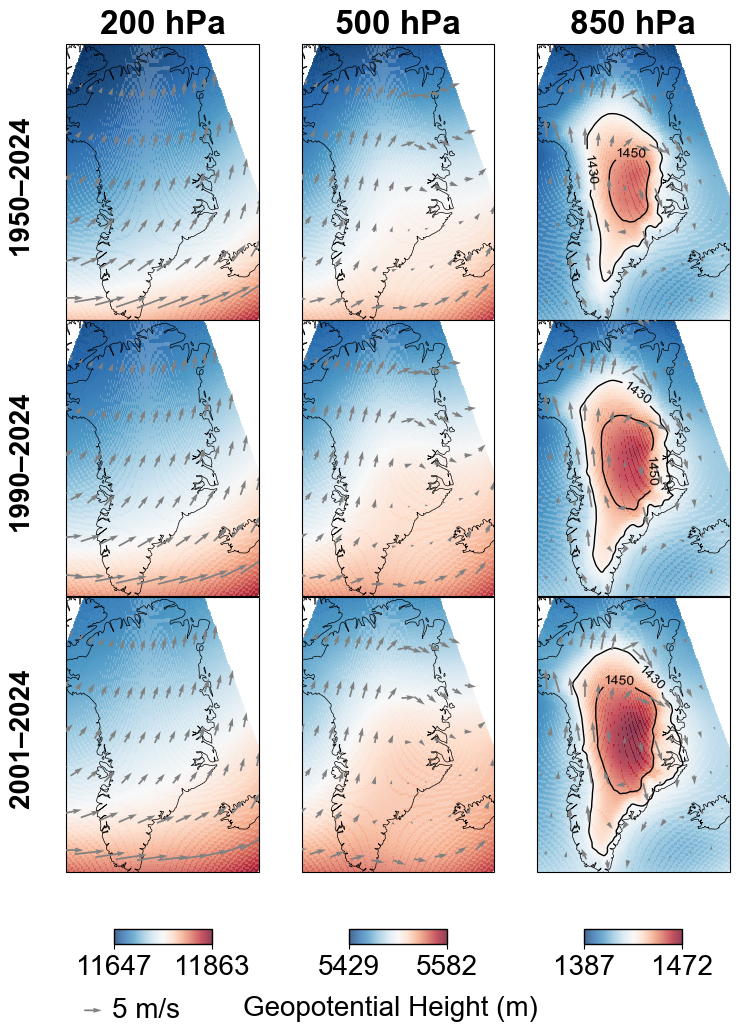

In [6]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys

# ===================== 1. 数据加载与 JJA 气候态均值 =====================
def load_and_preprocess_means(path, levels):
    try:
        ds = xr.open_dataset(path, chunks={'valid_time': 100})
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})

        # 自动识别纬度降序 (90 -> 55)
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lat_slice = slice(84, 59) if is_descending else slice(59, 84)

        # 裁剪变量与空间（保持延迟计算）
        ds_sub = ds[['z', 'u', 'v']].sel(
            pressure_level=levels,
            longitude=slice(-75, -10),
            latitude=lat_slice
        )

        # z: geopotential -> height (m)
        ds_sub["z"] = ds_sub["z"] / 9.80665

        def jja_mean(start, end):
            sub = ds_sub.sel(valid_time=slice(start, end))
            sub = sub.sel(valid_time=sub.valid_time.dt.month.isin([6, 7, 8]))
            return sub.mean("valid_time").compute()

        print("正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...")
        m_1950_2024 = jja_mean("1950-01-01", "2024-12-31")
        m_1990_2024 = jja_mean("1990-01-01", "2024-12-31")
        m_2001_2024 = jja_mean("2001-01-01", "2024-12-31")

        return m_1950_2024, m_1990_2024, m_2001_2024

    except Exception as e:
        print(f"数据初始化失败: {e}")
        sys.exit(1)

# ===================== 2. 样式配置 (Arial 20pt) =====================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 20,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

LEVELS = [200, 500, 850]
m1, m2, m3 = load_and_preprocess_means(
    r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc", LEVELS
)

# 投影：兰伯特投影
map_proj = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# ===================== 3. 统一每个气压层的色标范围（跨三行一致） =====================
vlims = {}
for lev in LEVELS:
    z_all = np.concatenate([
        np.ravel(m1.sel(pressure_level=lev).z.values),
        np.ravel(m2.sel(pressure_level=lev).z.values),
        np.ravel(m3.sel(pressure_level=lev).z.values),
    ])
    z_all = z_all[np.isfinite(z_all)]
    vlims[lev] = (float(z_all.min()), float(z_all.max()))

# ===================== 4. 绘图渲染（三行三列） =====================
# 缩窄整图宽度，左右边距极小
fig = plt.figure(figsize=(7.5, 12))
gs = fig.add_gridspec(
    3, 3,
    wspace=0.001, hspace=0.001,
    left=0.04, right=0.98,      # 左右贴边
    top=0.955, bottom=0.265
)

rows = [
    ("1950–2024 ", m1),
    ("1990–2024 ", m2),
    ("2001–2024 ", m3),
]

col_mappables = [None] * 3
last_q = None

for r, (row_label, r_ds) in enumerate(rows):
    for c, lev in enumerate(LEVELS):
        ax = fig.add_subplot(gs[r, c], projection=map_proj)
        ax.set_extent([-58, -18, 59.5, 83.5], crs=data_proj)

        data = r_ds.sel(pressure_level=lev)
        vmin, vmax = vlims[lev]

        im = ax.pcolormesh(
            data.longitude, data.latitude, data.z,
            transform=data_proj, cmap='RdBu_r',
            vmin=vmin, vmax=vmax,
            shading='auto', rasterized=True, alpha=0.75
        )
        if r == 0:
            col_mappables[c] = (im, vmin, vmax)

        # 在850 hPa列（c==2）添加等值线
        if lev == 850:
            cs = ax.contour(
                data.longitude, data.latitude, data.z,
                levels=[1430, 1450],
                colors='black',
                linewidths=1,
                transform=data_proj,
                zorder=4
            )
            ax.clabel(cs, inline=True, fontsize=10, fmt='%g')

        # 箭头
        q_ds = data.isel(latitude=slice(None, None, 15), longitude=slice(None, None, 18))
        last_q = ax.quiver(
            q_ds.longitude.values, q_ds.latitude.values,
            q_ds.u.values, q_ds.v.values,
            transform=data_proj, color='grey',
            scale=55, width=0.009, headwidth=3, zorder=5
        )

        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')

        # 列标题
        if r == 0:
            ax.set_title(f"{int(lev)} hPa", pad=8, weight='bold')

        # 行标题用 fig.text（只在第一列时添加）
        if c == 0:
            row_y = gs[r, 0].get_position(fig).y0 + gs[r, 0].get_position(fig).height / 2
            fig.text(
                0.01, row_y, row_label,
                rotation=90, va='center', ha='center', weight='bold', fontsize=20
            )

# ===================== 5. 底部：每列色标 + 单位 + 风矢量图例 =====================
# 色标位置
CBAR_Y = 0.205
CBAR_H = 0.013

for i, (m, v_min, v_max) in enumerate(col_mappables):
    pos = gs[2, i].get_position(fig)
    cax_w = pos.width * 0.42
    cax_x = pos.x0 + (pos.width - cax_w) / 2
    cax = fig.add_axes([cax_x, CBAR_Y, cax_w, CBAR_H])

    cb = plt.colorbar(m, cax=cax, orientation='horizontal')
    cb.set_ticks([v_min, v_max])
    cb.ax.set_xticklabels([f"{v_min:.0f}", f"{v_max:.0f}"])
    cb.outline.set_linewidth(1)

# 单位标签
fig.text(
    0.5, 0.152, "Geopotential Height (m)",
    ha='center', va='center', fontsize=20, weight='normal'
)

# 风速图例
if last_q is not None:
    plt.quiverkey(
        last_q,
        X=0.115, Y=0.15, U=5, label="5 m/s",
        labelpos='E', coordinates='figure',
        fontproperties={'family': 'Arial', 'size': 20, 'weight': 'normal'}
    )

plt.show()

In [5]:
import xarray as xr
import numpy as np
import sys

# ===================== 1. 数据加载与 JJA 气候态均值 =====================
def load_and_calculate_changes(path, levels):
    try:
        ds = xr.open_dataset(path, chunks={'time': 100})
        
        # 检查坐标名称
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})
        
        # 检查气压层坐标名称
        pressure_coord = None
        for name in ['pressure_level', 'level', 'plev', 'pressure', 'isobaricInhPa']:
            if name in ds.coords or name in ds.dims:
                pressure_coord = name
                break
        
        if pressure_coord and pressure_coord != 'pressure_level':
            ds = ds.rename({pressure_coord: 'pressure_level'})
        
        # 检查时间坐标名称
        time_coord = None
        for name in ['time', 'valid_time', 't']:
            if name in ds.coords or name in ds.dims:
                time_coord = name
                break
        
        if time_coord and time_coord != 'time':
            ds = ds.rename({time_coord: 'time'})

        # 自动识别纬度降序
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lat_slice = slice(85, 58) if is_descending else slice(58, 85)

        # 裁剪到格陵兰区域（调整经度范围）
        ds_sub = ds.sel(
            pressure_level=levels,
            longitude=slice(-75, -10),
            latitude=lat_slice
        )

        # 转换单位
        # Geopotential (z) -> height (m)
        if 'z' in ds_sub:
            ds_sub["z"] = ds_sub["z"] / 9.80665
        
        # Specific humidity 通常已经是 kg/kg，无需转换
        # Vertical velocity 保持 Pa/s

        def jja_mean(start, end):
            sub = ds_sub.sel(time=slice(start, end))
            sub = sub.sel(time=sub.time.dt.month.isin([6, 7, 8]))
            return sub.mean("time").compute()

        print("=" * 80)
        print("正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...")
        print("=" * 80)
        
        m_1950_2024 = jja_mean("1950-01-01", "2024-12-31")
        m_1990_2024 = jja_mean("1990-01-01", "2024-12-31")
        m_2001_2024 = jja_mean("2001-01-01", "2024-12-31")

        print("✓ 均值计算完成\n")

        # 计算变化量（anomaly）
        print("=" * 80)
        print("正在计算变化量...")
        print("=" * 80)
        
        change_1990 = m_1990_2024 - m_1950_2024  # 1990-2024 相对 1950-2024 的变化
        change_2001 = m_2001_2024 - m_1950_2024  # 2001-2024 相对 1950-2024 的变化
        
        print("✓ 变化量计算完成\n")

        return m_1950_2024, m_1990_2024, m_2001_2024, change_1990, change_2001

    except Exception as e:
        print(f"数据初始化失败: {e}")
        import traceback
        traceback.print_exc()
        sys.exit(1)

# ===================== 2. 统计分析与打印 =====================
def print_statistics(data_dict, levels):
    """打印每个变量、每个气压层、每个时期的统计信息"""
    
    variables = {
        'z': {'name': 'Geopotential Height', 'unit': 'm'},
        'q': {'name': 'Specific Humidity', 'unit': 'kg/kg'},
        'w': {'name': 'Vertical Velocity', 'unit': 'Pa/s'}
    }
    
    periods = {
        'm_1950_2024': '1950-2024',
        'm_1990_2024': '1990-2024',
        'm_2001_2024': '2001-2024',
        'change_1990': 'Change (1990-2024 minus 1950-2024)',
        'change_2001': 'Change (2001-2024 minus 1950-2024)'
    }
    
    for var_code, var_info in variables.items():
        print("\n" + "=" * 80)
        print(f"【{var_info['name']} ({var_info['unit']})】")
        print("=" * 80)
        
        # 检查变量是否存在
        var_exists = False
        for period_key in data_dict.keys():
            if var_code in data_dict[period_key]:
                var_exists = True
                break
        
        if not var_exists:
            print(f"⚠ 变量 '{var_code}' 不存在于数据集中\n")
            continue
        
        # 按气压层组织输出
        for lev in levels:
            print(f"\n{'-' * 80}")
            print(f"气压层: {int(lev)} hPa")
            print(f"{'-' * 80}")
            print(f"{'时期':<40} {'最小值':>12} {'最大值':>12} {'平均值':>12}")
            print(f"{'-' * 80}")
            
            for period_key, period_name in periods.items():
                if var_code not in data_dict[period_key]:
                    continue
                    
                data = data_dict[period_key][var_code].sel(pressure_level=lev).values
                data = data[np.isfinite(data)]
                
                if len(data) > 0:
                    print(f"{period_name:<40} {data.min():12.6f} {data.max():12.6f} {data.mean():12.6f}")
                else:
                    print(f"{period_name:<40} {'N/A':>12} {'N/A':>12} {'N/A':>12}")

# ===================== 3. 主程序 =====================
if __name__ == "__main__":
    
    # 设置参数
    FILE_PATH = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
    LEVELS = [200, 500, 800, 1000]  # 根据你的数据，使用这四个气压层
    
    print("\n" + "=" * 80)
    print("开始处理数据...")
    print(f"文件路径: {FILE_PATH}")
    print(f"气压层: {LEVELS} hPa")
    print("=" * 80 + "\n")
    
    # 加载数据并计算
    m1, m2, m3, ch1, ch2 = load_and_calculate_changes(FILE_PATH, LEVELS)
    
    # 组织数据
    data_dict = {
        'm_1950_2024': m1,
        'm_1990_2024': m2,
        'm_2001_2024': m3,
        'change_1990': ch1,
        'change_2001': ch2
    }
    
    # 打印统计信息
    print_statistics(data_dict, LEVELS)
    
    print("\n" + "=" * 80)
    print("处理完成！")
    print("=" * 80)
    
    # 保存数据供后续可视化使用
    print("\n提示：数据已加载到内存，可以继续用于绘图")
    print("变量：m1 (1950-2024), m2 (1990-2024), m3 (2001-2024)")
    print("变化：ch1 (1990-2024变化), ch2 (2001-2024变化)")


开始处理数据...
文件路径: C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc
气压层: [200, 500, 800, 1000] hPa

正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...
✓ 均值计算完成

正在计算变化量...
✓ 变化量计算完成


【Geopotential Height (m)】

--------------------------------------------------------------------------------
气压层: 200 hPa
--------------------------------------------------------------------------------
时期                                                最小值          最大值          平均值
--------------------------------------------------------------------------------
1950-2024                                11645.514648 11872.372070 11716.683594
1990-2024                                11657.261719 11877.253906 11731.579102
2001-2024                                11672.687500 11877.620117 11745.271484
Change (1990-2024 minus 1950-2024)           3.126953    24.360352    14.894144
Change (2001-2024 minus 1950-2024)           3.807617    34.979492    28.586887

-------------------------

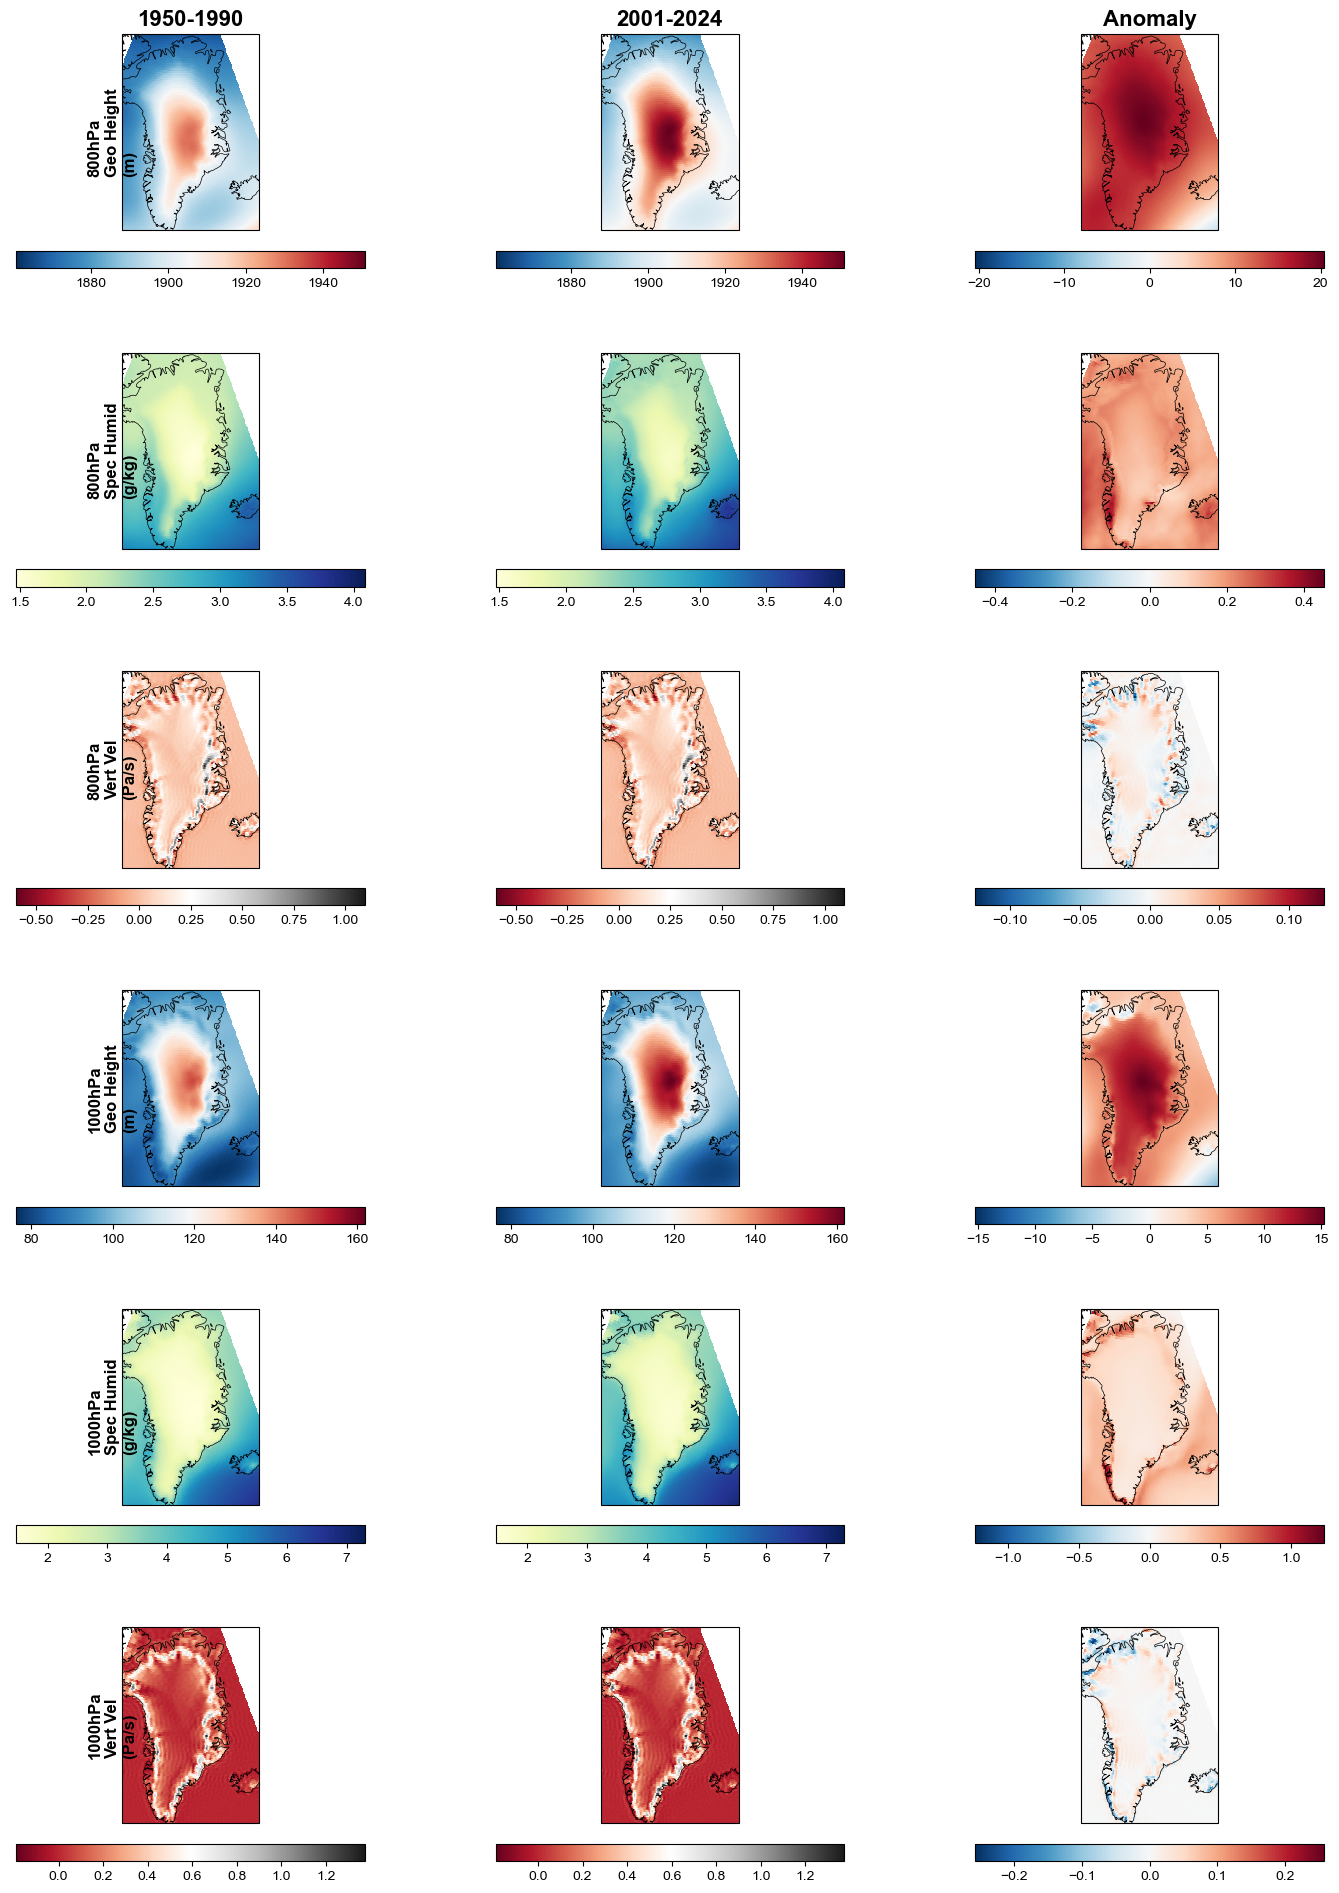

In [10]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===================== 1. 数据处理 =====================
def get_processed_data(path, levels):
    ds = xr.open_dataset(path)
    rename_map = {old: new for old, new in [('lat', 'latitude'), ('lon', 'longitude'), 
                  ('level', 'pressure_level'), ('plev', 'pressure_level'), ('valid_time', 'time')] if old in ds.coords}
    ds = ds.rename(rename_map)
    
    is_desc = bool(ds.latitude[0] > ds.latitude[-1])
    lat_s = slice(85, 58) if is_desc else slice(58, 85)
    ds = ds.sel(pressure_level=levels, longitude=slice(-75, -10), latitude=lat_s)
    
    if 'z' in ds: ds['z'] = ds['z'] / 9.80665
    return ds

def get_jja_mean(ds, start, end):
    sub = ds.sel(time=slice(start, end))
    return sub.sel(time=sub.time.dt.month.isin([6, 7, 8])).mean("time").compute()

# 加载数据
LEVELS = [800, 1000]
ds_all = get_processed_data(r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc", LEVELS)

m1 = get_jja_mean(ds_all, "1950-01-01", "1990-12-31")
m2 = get_jja_mean(ds_all, "2001-01-01", "2024-12-31")
anom = m2 - m1

# ===================== 2. 绘图配置 =====================
variables = [
    {'code': 'z', 'name': 'Geo Height', 'unit': 'm', 'cmap': 'RdBu_r'},
    {'code': 'q', 'name': 'Spec Humid', 'unit': 'g/kg', 'cmap': 'YlGnBu', 'scale': 1e3},
    {'code': 'w', 'name': 'Vert Vel', 'unit': 'Pa/s', 'cmap': 'RdGy', 'scale': 1}
]

fig = plt.figure(figsize=(18, 24))
gs = fig.add_gridspec(6, 3, wspace=0.1, hspace=0.25)
map_proj = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# 遍历 气压层 -> 变量 -> 指标
for l_idx, lev in enumerate(LEVELS):
    for v_idx, var in enumerate(variables):
        row = l_idx * 3 + v_idx
        v_code = var['code']
        scale = var.get('scale', 1.0)
        
        # 提取当前层和变量的数据
        d1 = m1[v_code].sel(pressure_level=lev) * scale
        d2 = m2[v_code].sel(pressure_level=lev) * scale
        da = anom[v_code].sel(pressure_level=lev) * scale
        
        # 设定色标范围
        v_min, v_max = min(d1.min(), d2.min()), max(d1.max(), d2.max())
        a_max = np.abs(da).max()
        
        plot_data = [d1, d2, da]
        vmins = [v_min, v_min, -a_max]
        vmaxs = [v_max, v_max, a_max]
        cmaps = [var['cmap'], var['cmap'], 'RdBu_r']
        
        for col in range(3):
            ax = fig.add_subplot(gs[row, col], projection=map_proj)
            ax.set_extent([-58, -18, 59.5, 83.5], crs=data_proj)
            ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
            
            im = ax.pcolormesh(plot_data[col].longitude, plot_data[col].latitude, plot_data[col],
                               transform=data_proj, cmap=cmaps[col],
                               vmin=vmins[col], vmax=vmaxs[col], shading='auto')
            
            # 标题与标注
            if row == 0: ax.set_title(['1950-1990', '2001-2024', 'Anomaly'][col], weight='bold', fontsize=16)
            if col == 0: 
                ax.text(-0.25, 0.5, f"{lev}hPa\n{var['name']}\n({var['unit']})", 
                        transform=ax.transAxes, rotation=90, va='center', weight='bold', fontsize=12)
            
            # 独立色标
            cb = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.08, shrink=0.8)
            cb.ax.tick_params(labelsize=10)

plt.show()

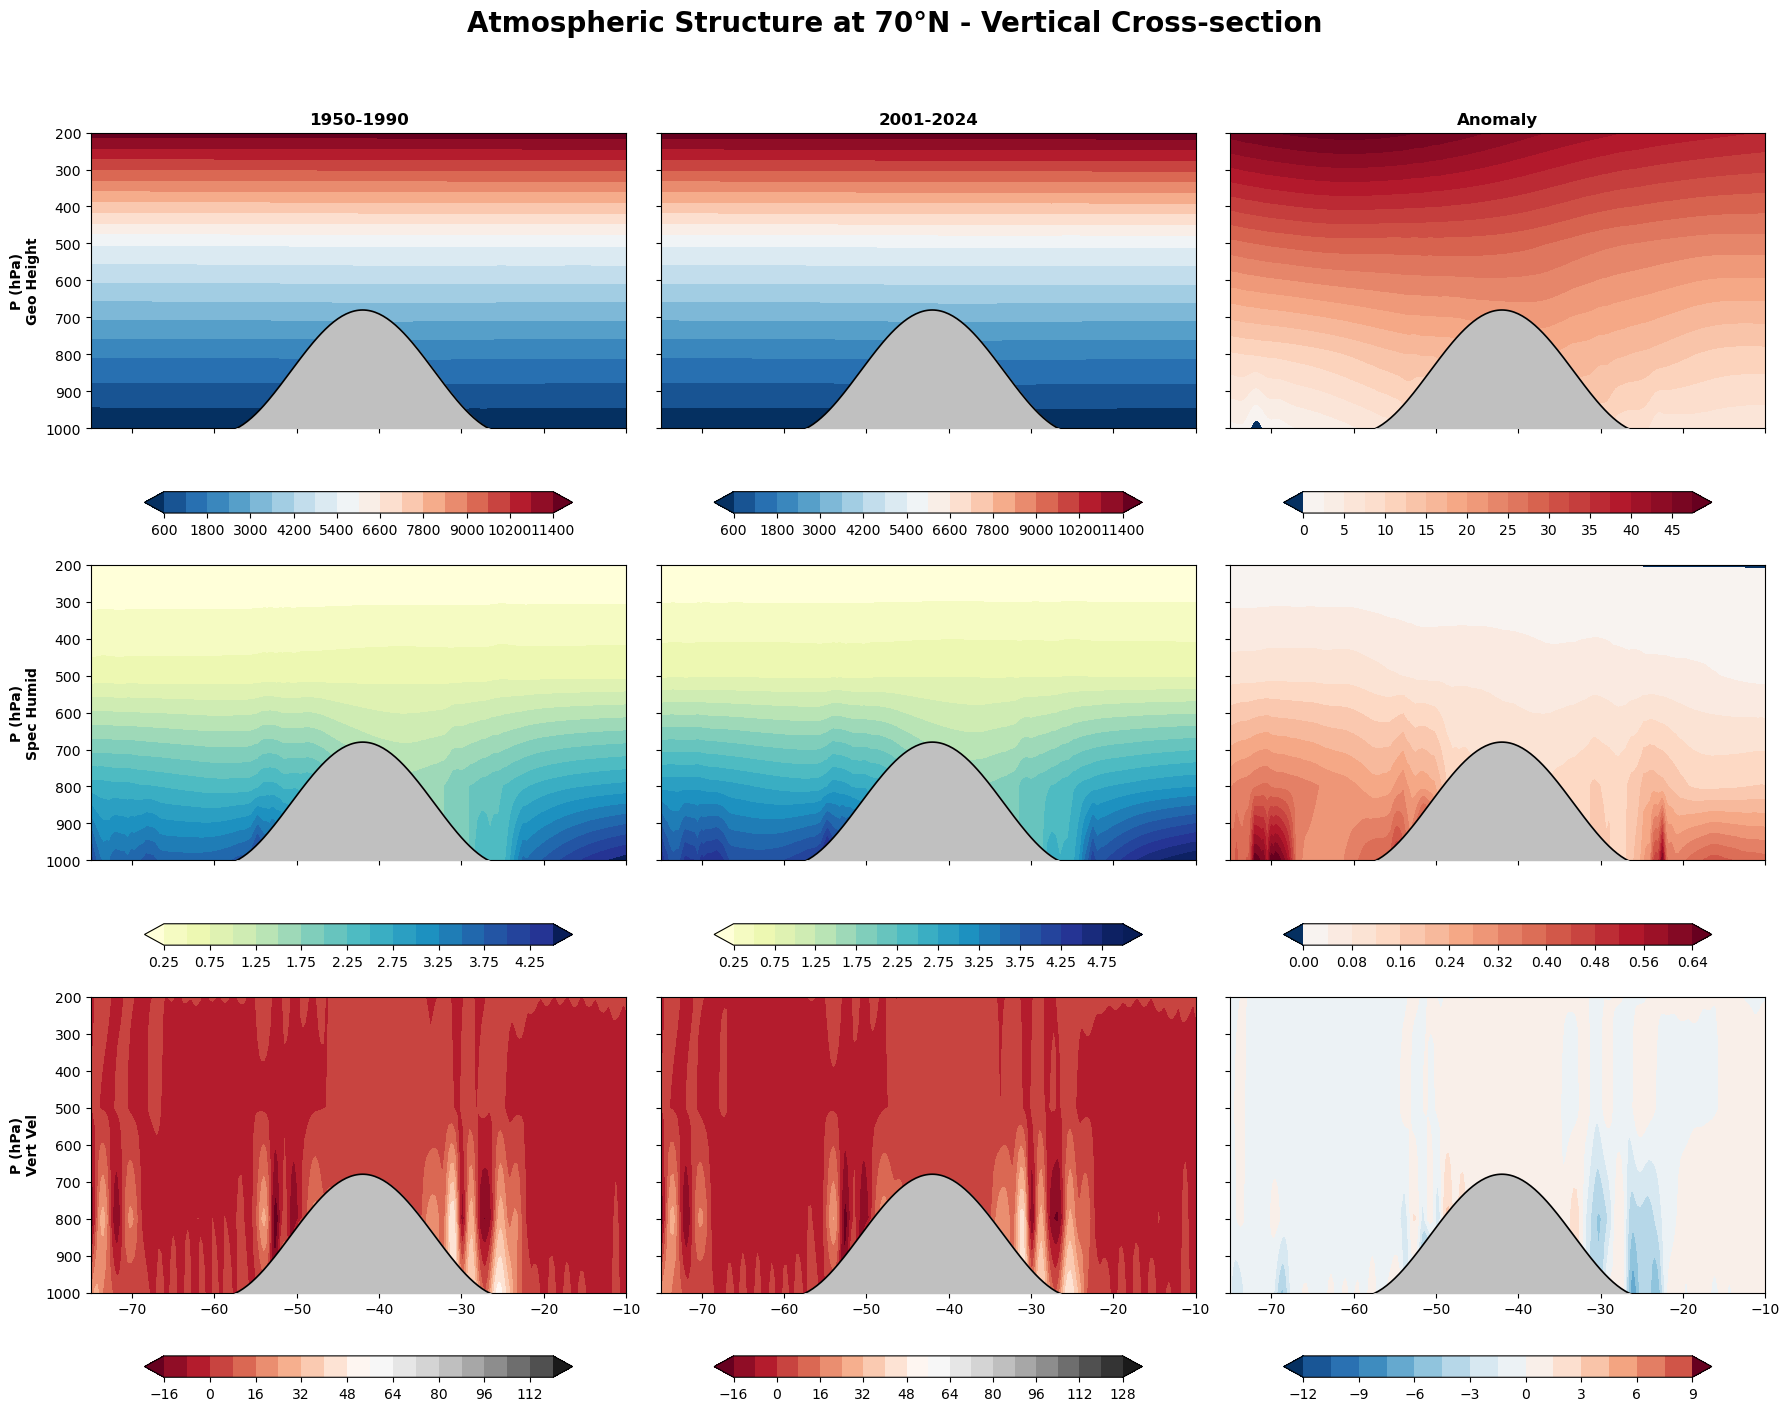

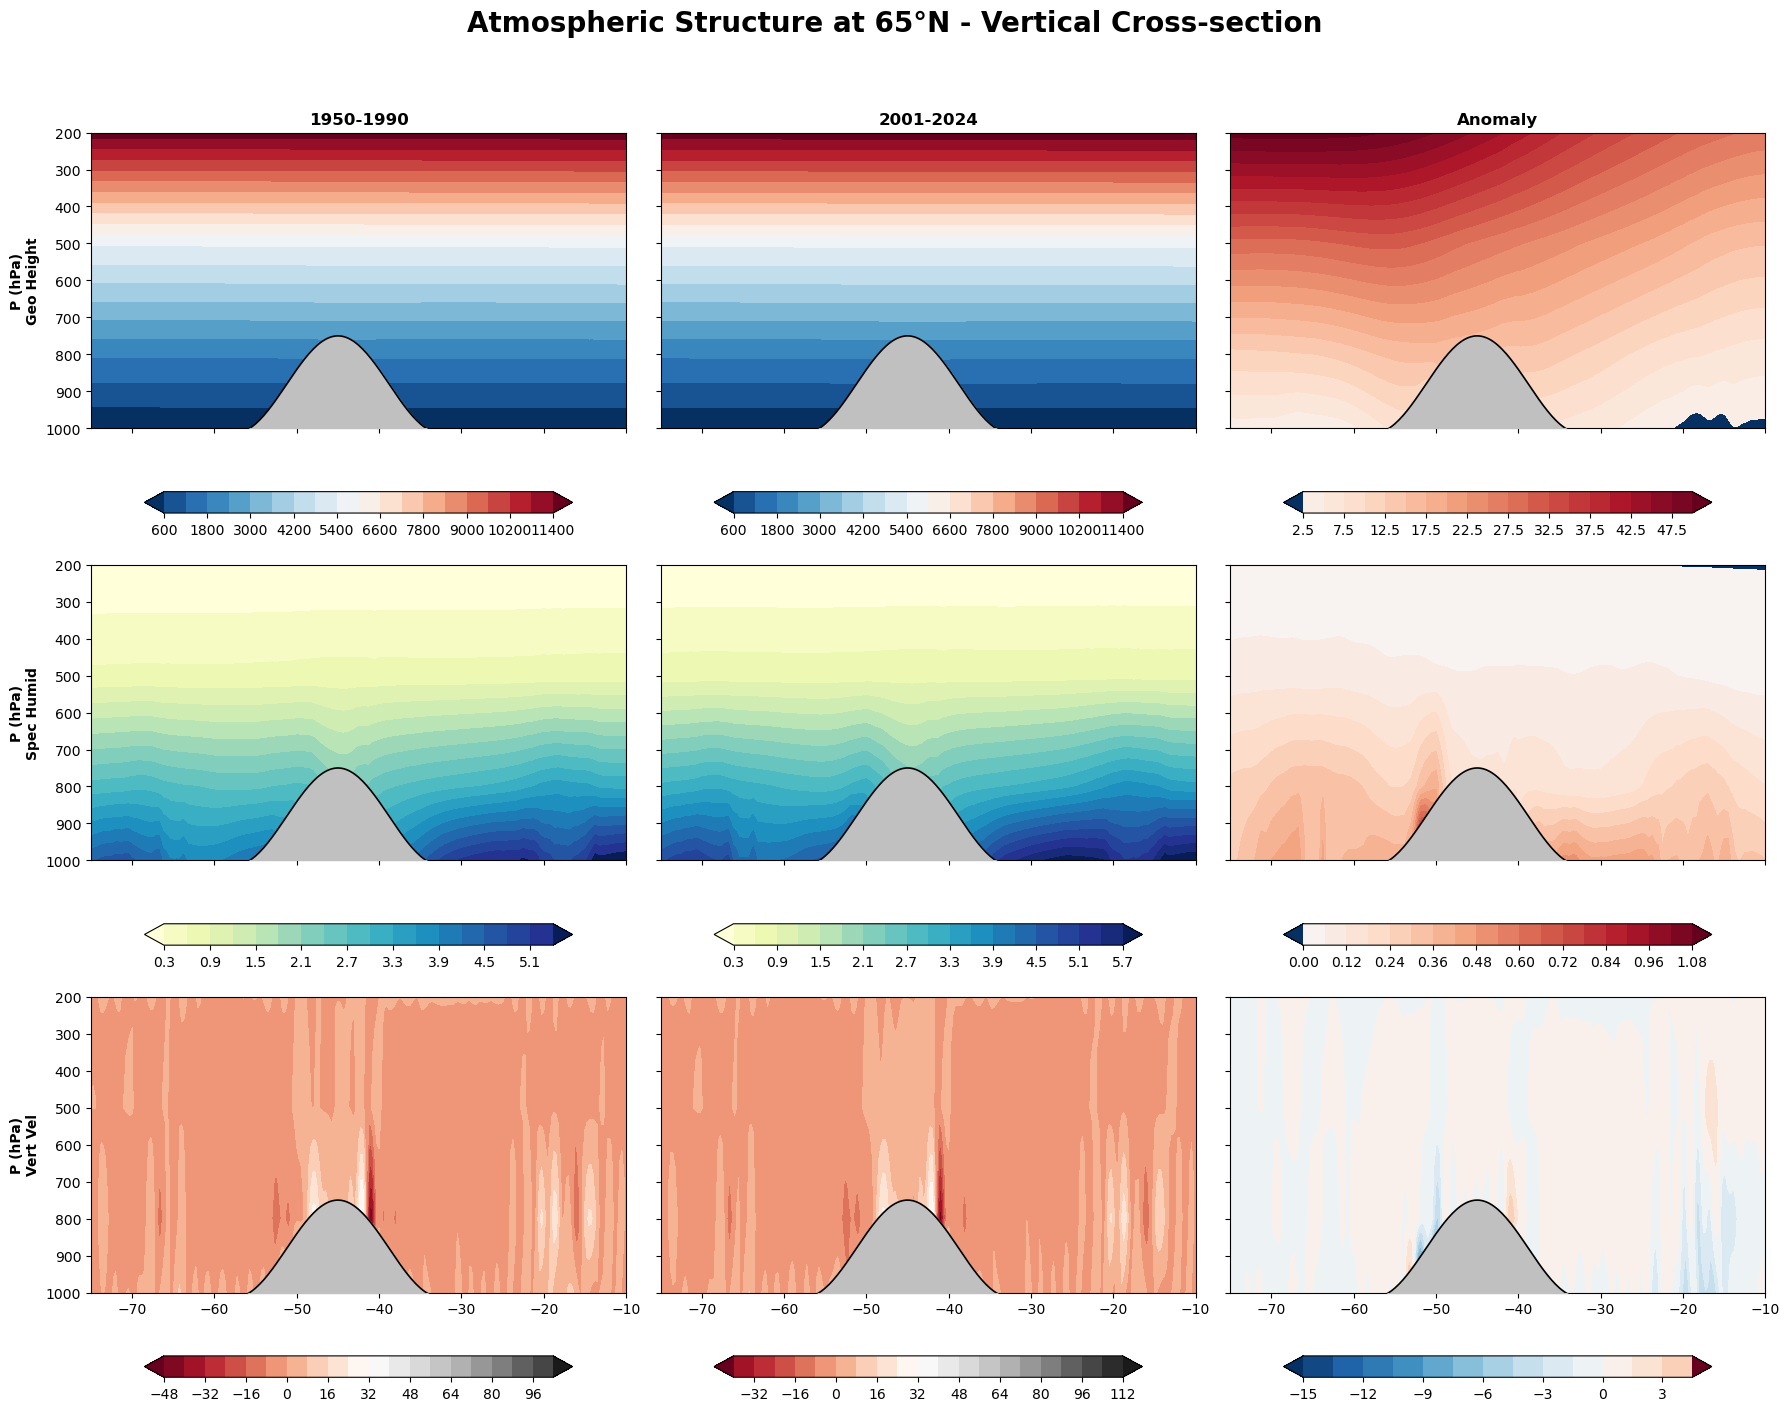

In [5]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# ===================== 1. 数据处理与剖面提取 =====================
def get_cross_section(ds_mean, lat_val):
    # 选取特定纬度并进行经度切片 (-75 to -10)
    return ds_mean.sel(latitude=lat_val, method='nearest').compute()

# 定义目标纬度和变量
TARGET_LATS = [70, 65]
VARIABLES = [
    {'code': 'z', 'name': 'Geo Height', 'cmap': 'RdBu_r', 'unit': 'm'},
    {'code': 'q', 'name': 'Spec Humid', 'cmap': 'YlGnBu', 'unit': 'g/kg', 'scale': 1e3},
    {'code': 'w', 'name': 'Vert Vel', 'cmap': 'RdGy', 'unit': 'Pa/s*100', 'scale': 100}
]

# 模拟地形（针对不同纬度可以微调，这里使用通用函数）
def get_topo(lons, lat):
    topo = np.full_like(lons, 1013.0)
    # 70N 冰盖较宽且高，65N 稍窄
    width = 35 if lat == 70 else 25
    center = -42 if lat == 70 else -45
    peak = 680 if lat == 70 else 750
    mask = (lons > (center - width/2)) & (lons < (center + width/2))
    topo[mask] = 1013 - (1013 - peak) * np.cos(np.pi * (lons[mask] - center) / width)**2
    return topo

# ===================== 2. 绘图：每个纬度一张大图 (3变量 x 3指标) =====================
for lat in TARGET_LATS:
    fig, axes = plt.subplots(3, 3, figsize=(18, 15), sharex=True, sharey=True)
    lons = m1.longitude.values
    topo_mask = get_topo(lons, lat)
    
    for r, var in enumerate(VARIABLES):
        v_code = var['code']
        scale = var.get('scale', 1.0)
        
        # 准备三列数据
        d1 = get_cross_section(m1, lat)[v_code] * scale
        d2 = get_cross_section(m2, lat)[v_code] * scale
        da = get_cross_section(anom, lat)[v_code] * scale
        
        # 设定色标范围
        v_min, v_max = min(d1.min(), d2.min()), max(d1.max(), d2.max())
        a_max = np.abs(da).max()
        
        plot_list = [d1, d2, da]
        vmins = [v_min, v_min, -a_max]
        vmaxs = [v_max, v_max, a_max]
        cmaps = [var['cmap'], var['cmap'], 'RdBu_r']
        
        for c in range(3):
            ax = axes[r, c]
            # 渲染填色
            im = ax.contourf(lons, LEVELS, plot_list[c], levels=20, 
                             cmap=cmaps[c], vmin=vmins[c], vmax=vmaxs[c], extend='both')
            
            # 地形遮罩
            ax.fill_between(lons, topo_mask, 1050, color='silver', zorder=10)
            ax.plot(lons, topo_mask, color='black', linewidth=1.2, zorder=11)
            
            # 坐标轴与标注
            ax.set_ylim(1000, 200)
            if r == 0: ax.set_title(['1950-1990', '2001-2024', 'Anomaly'][c], weight='bold')
            if c == 0: ax.set_ylabel(f"P (hPa)\n{var['name']}", weight='bold')
            
            plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.15, shrink=0.8)

    plt.suptitle(f"Atmospheric Structure at {lat}°N - Vertical Cross-section", fontsize=20, weight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

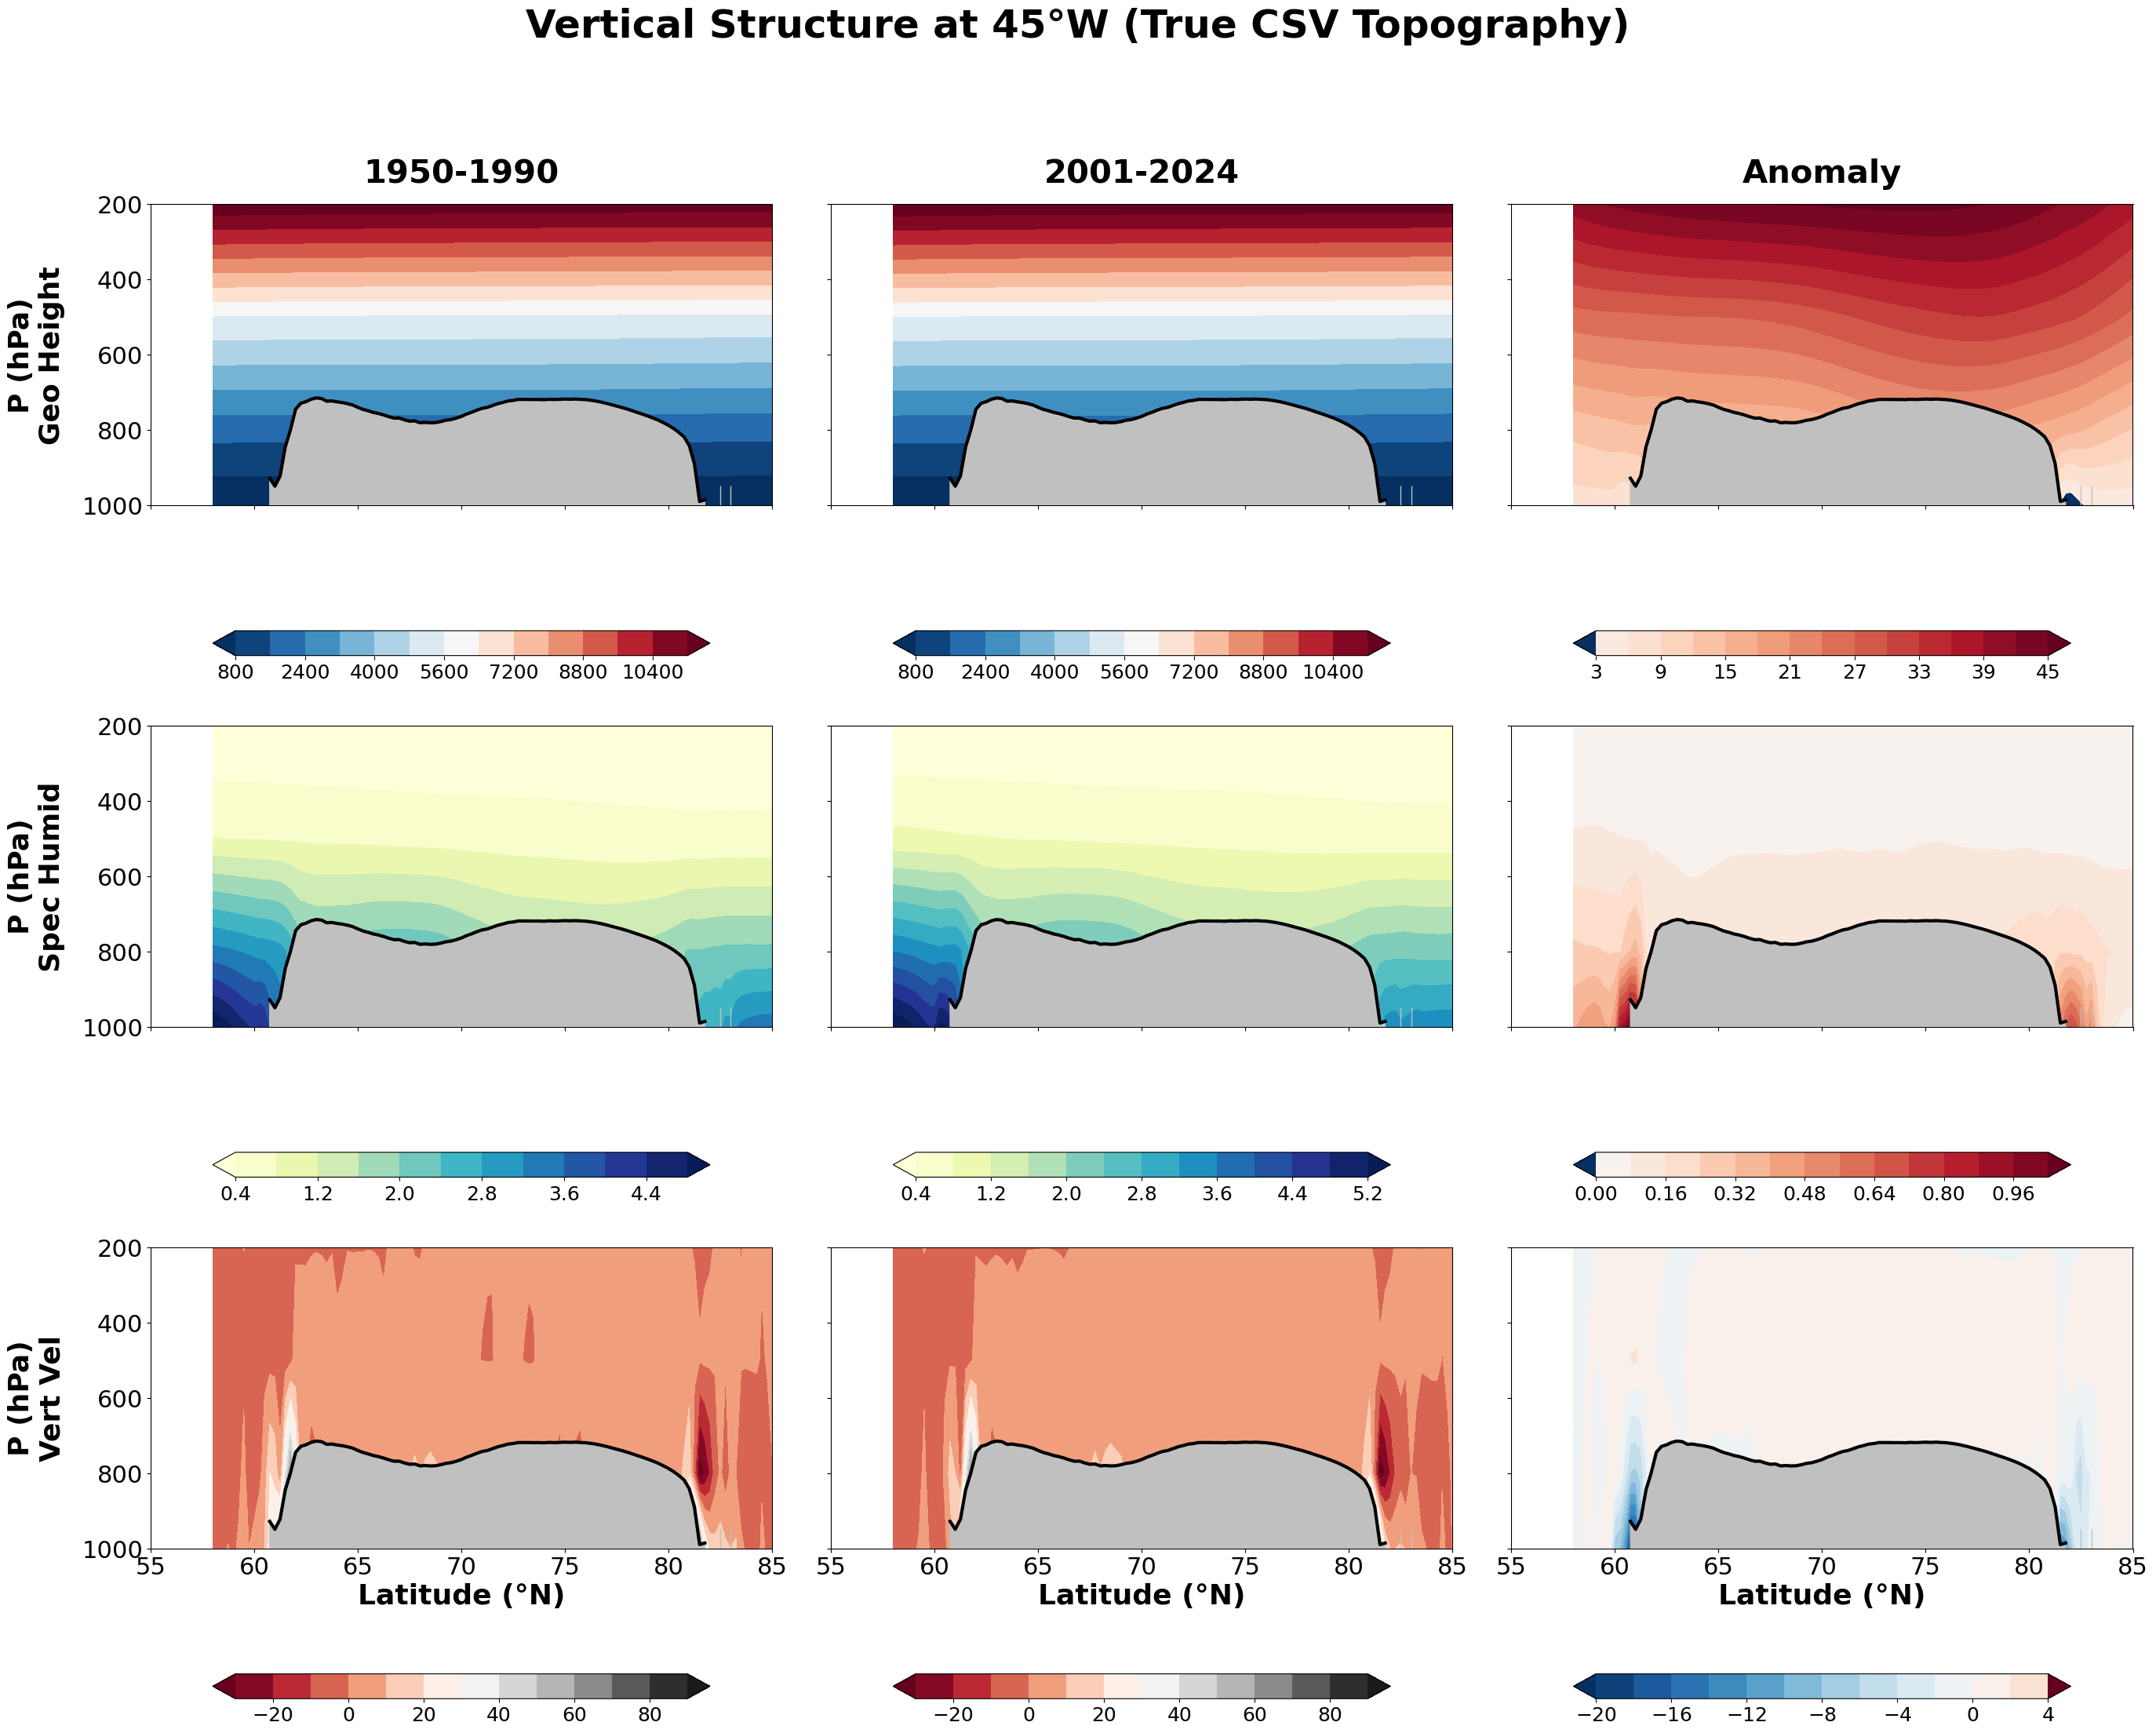

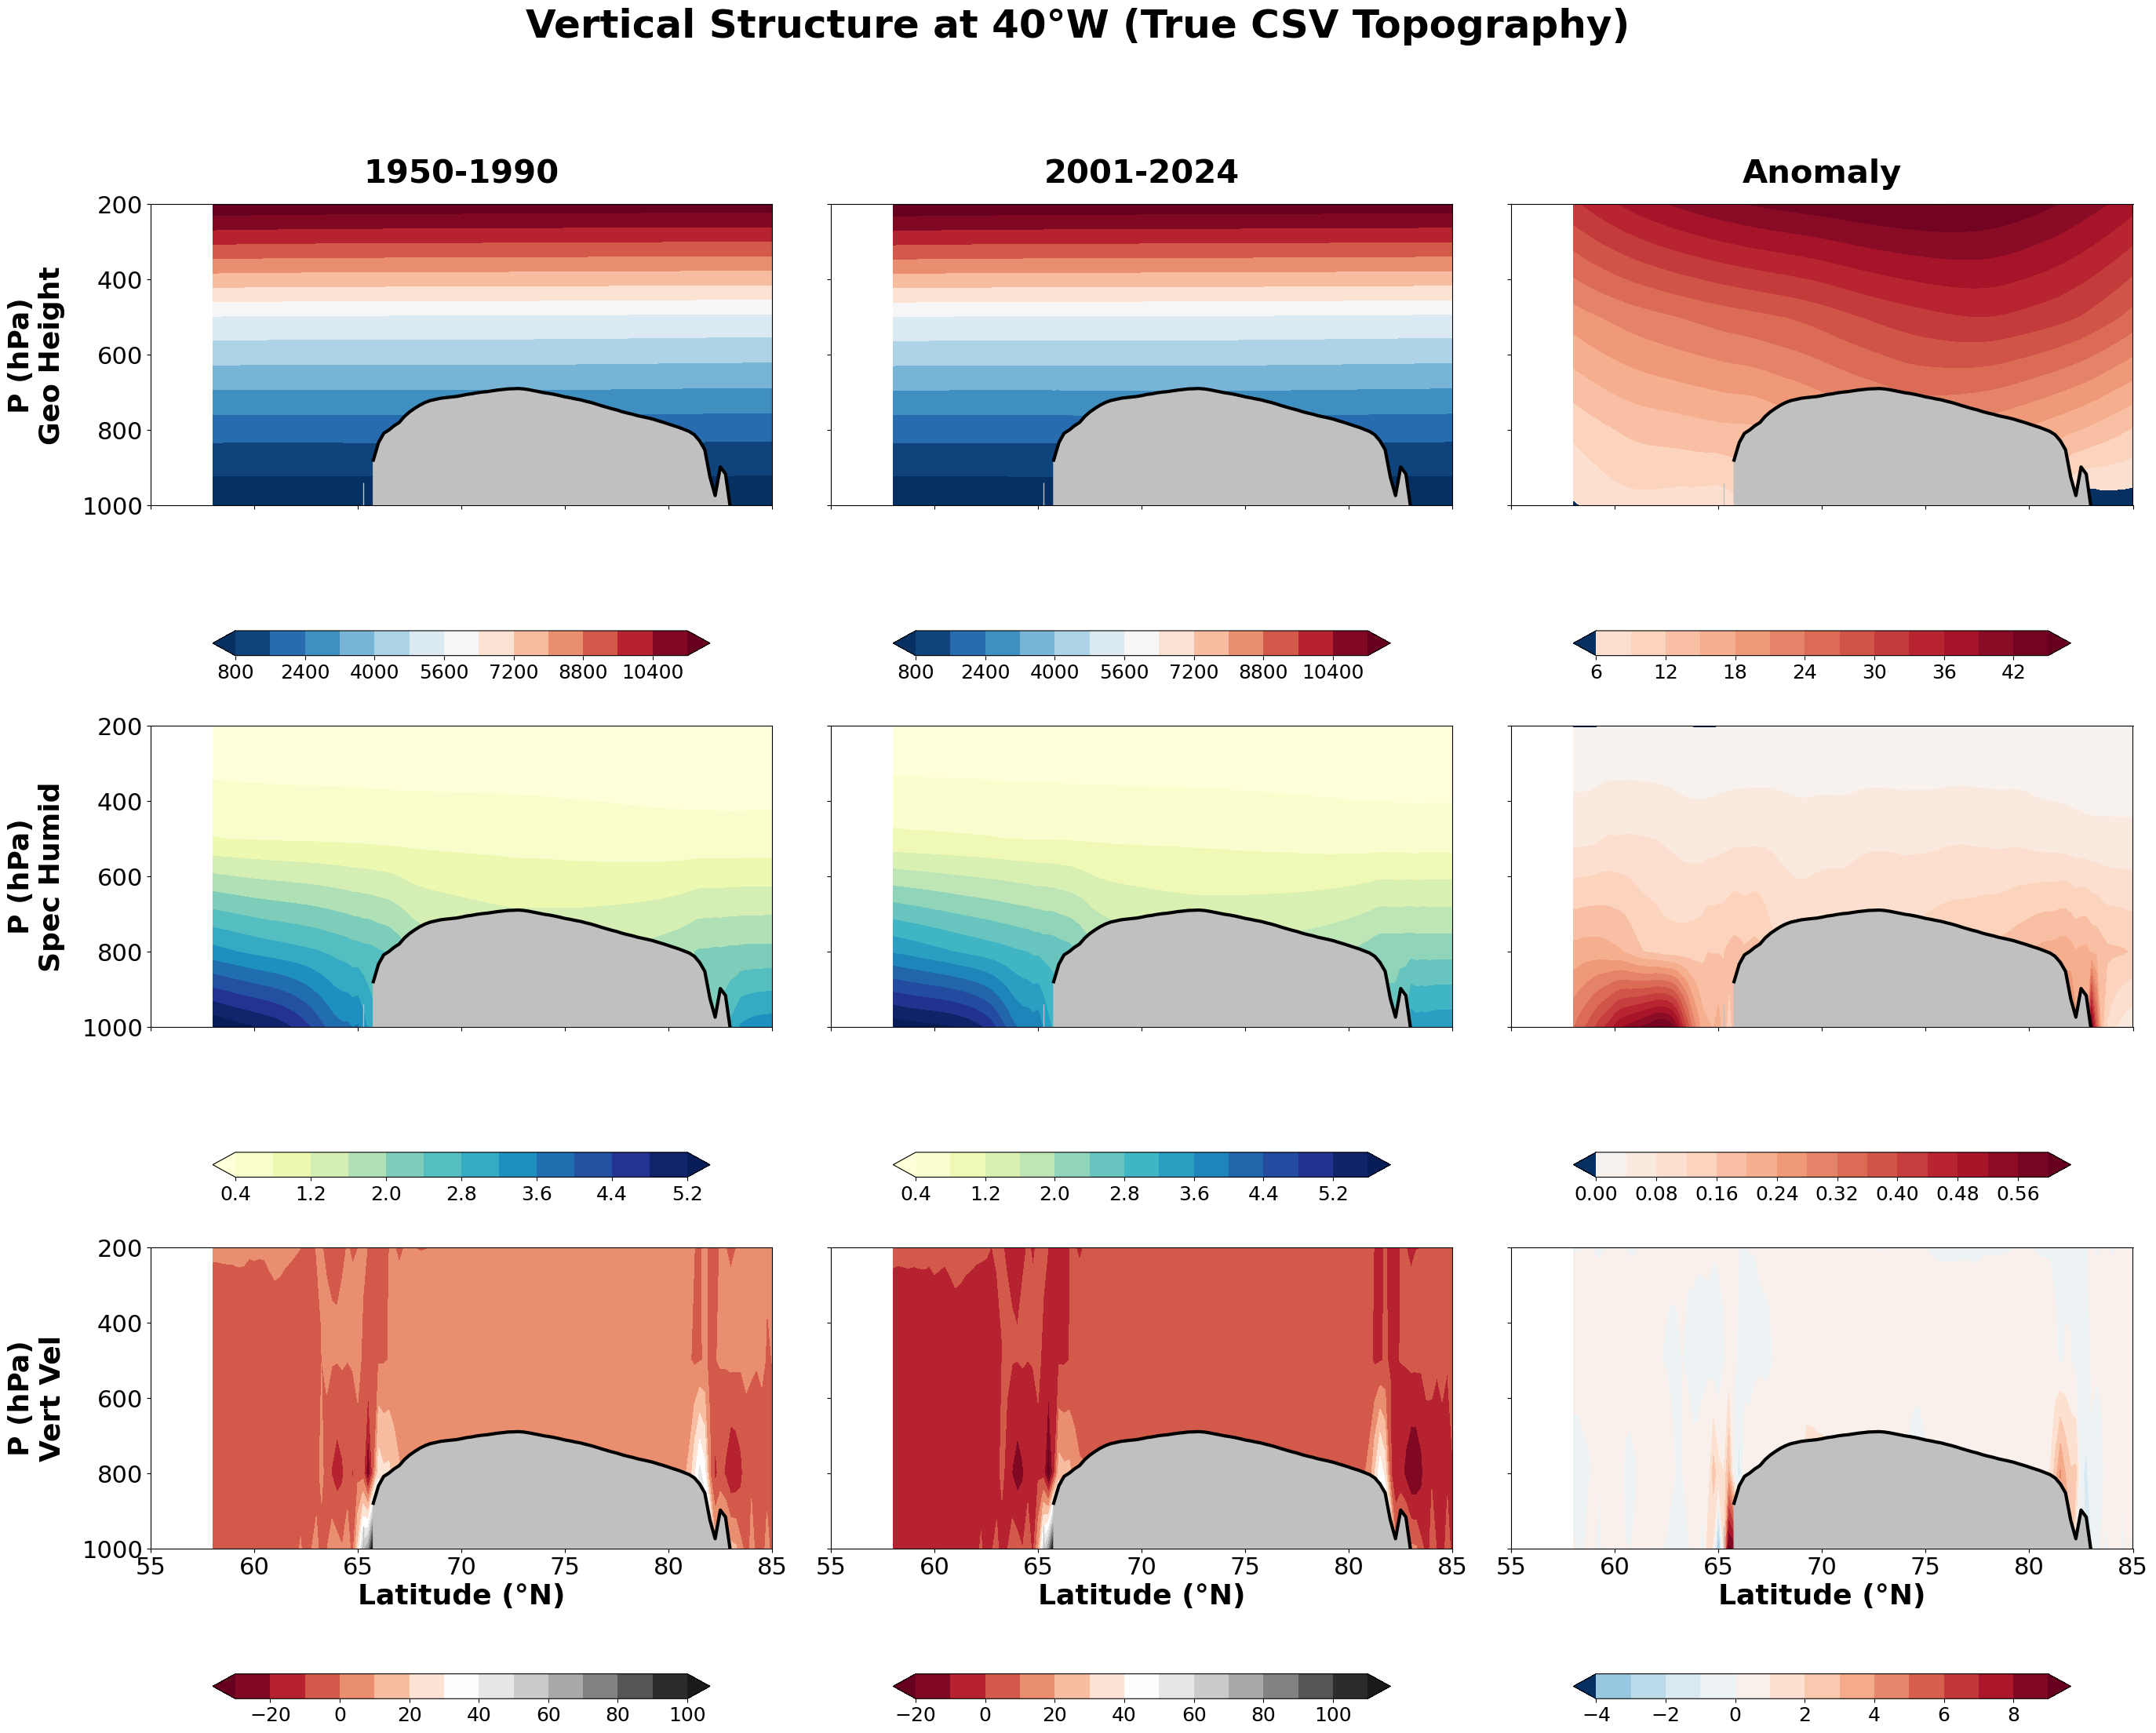

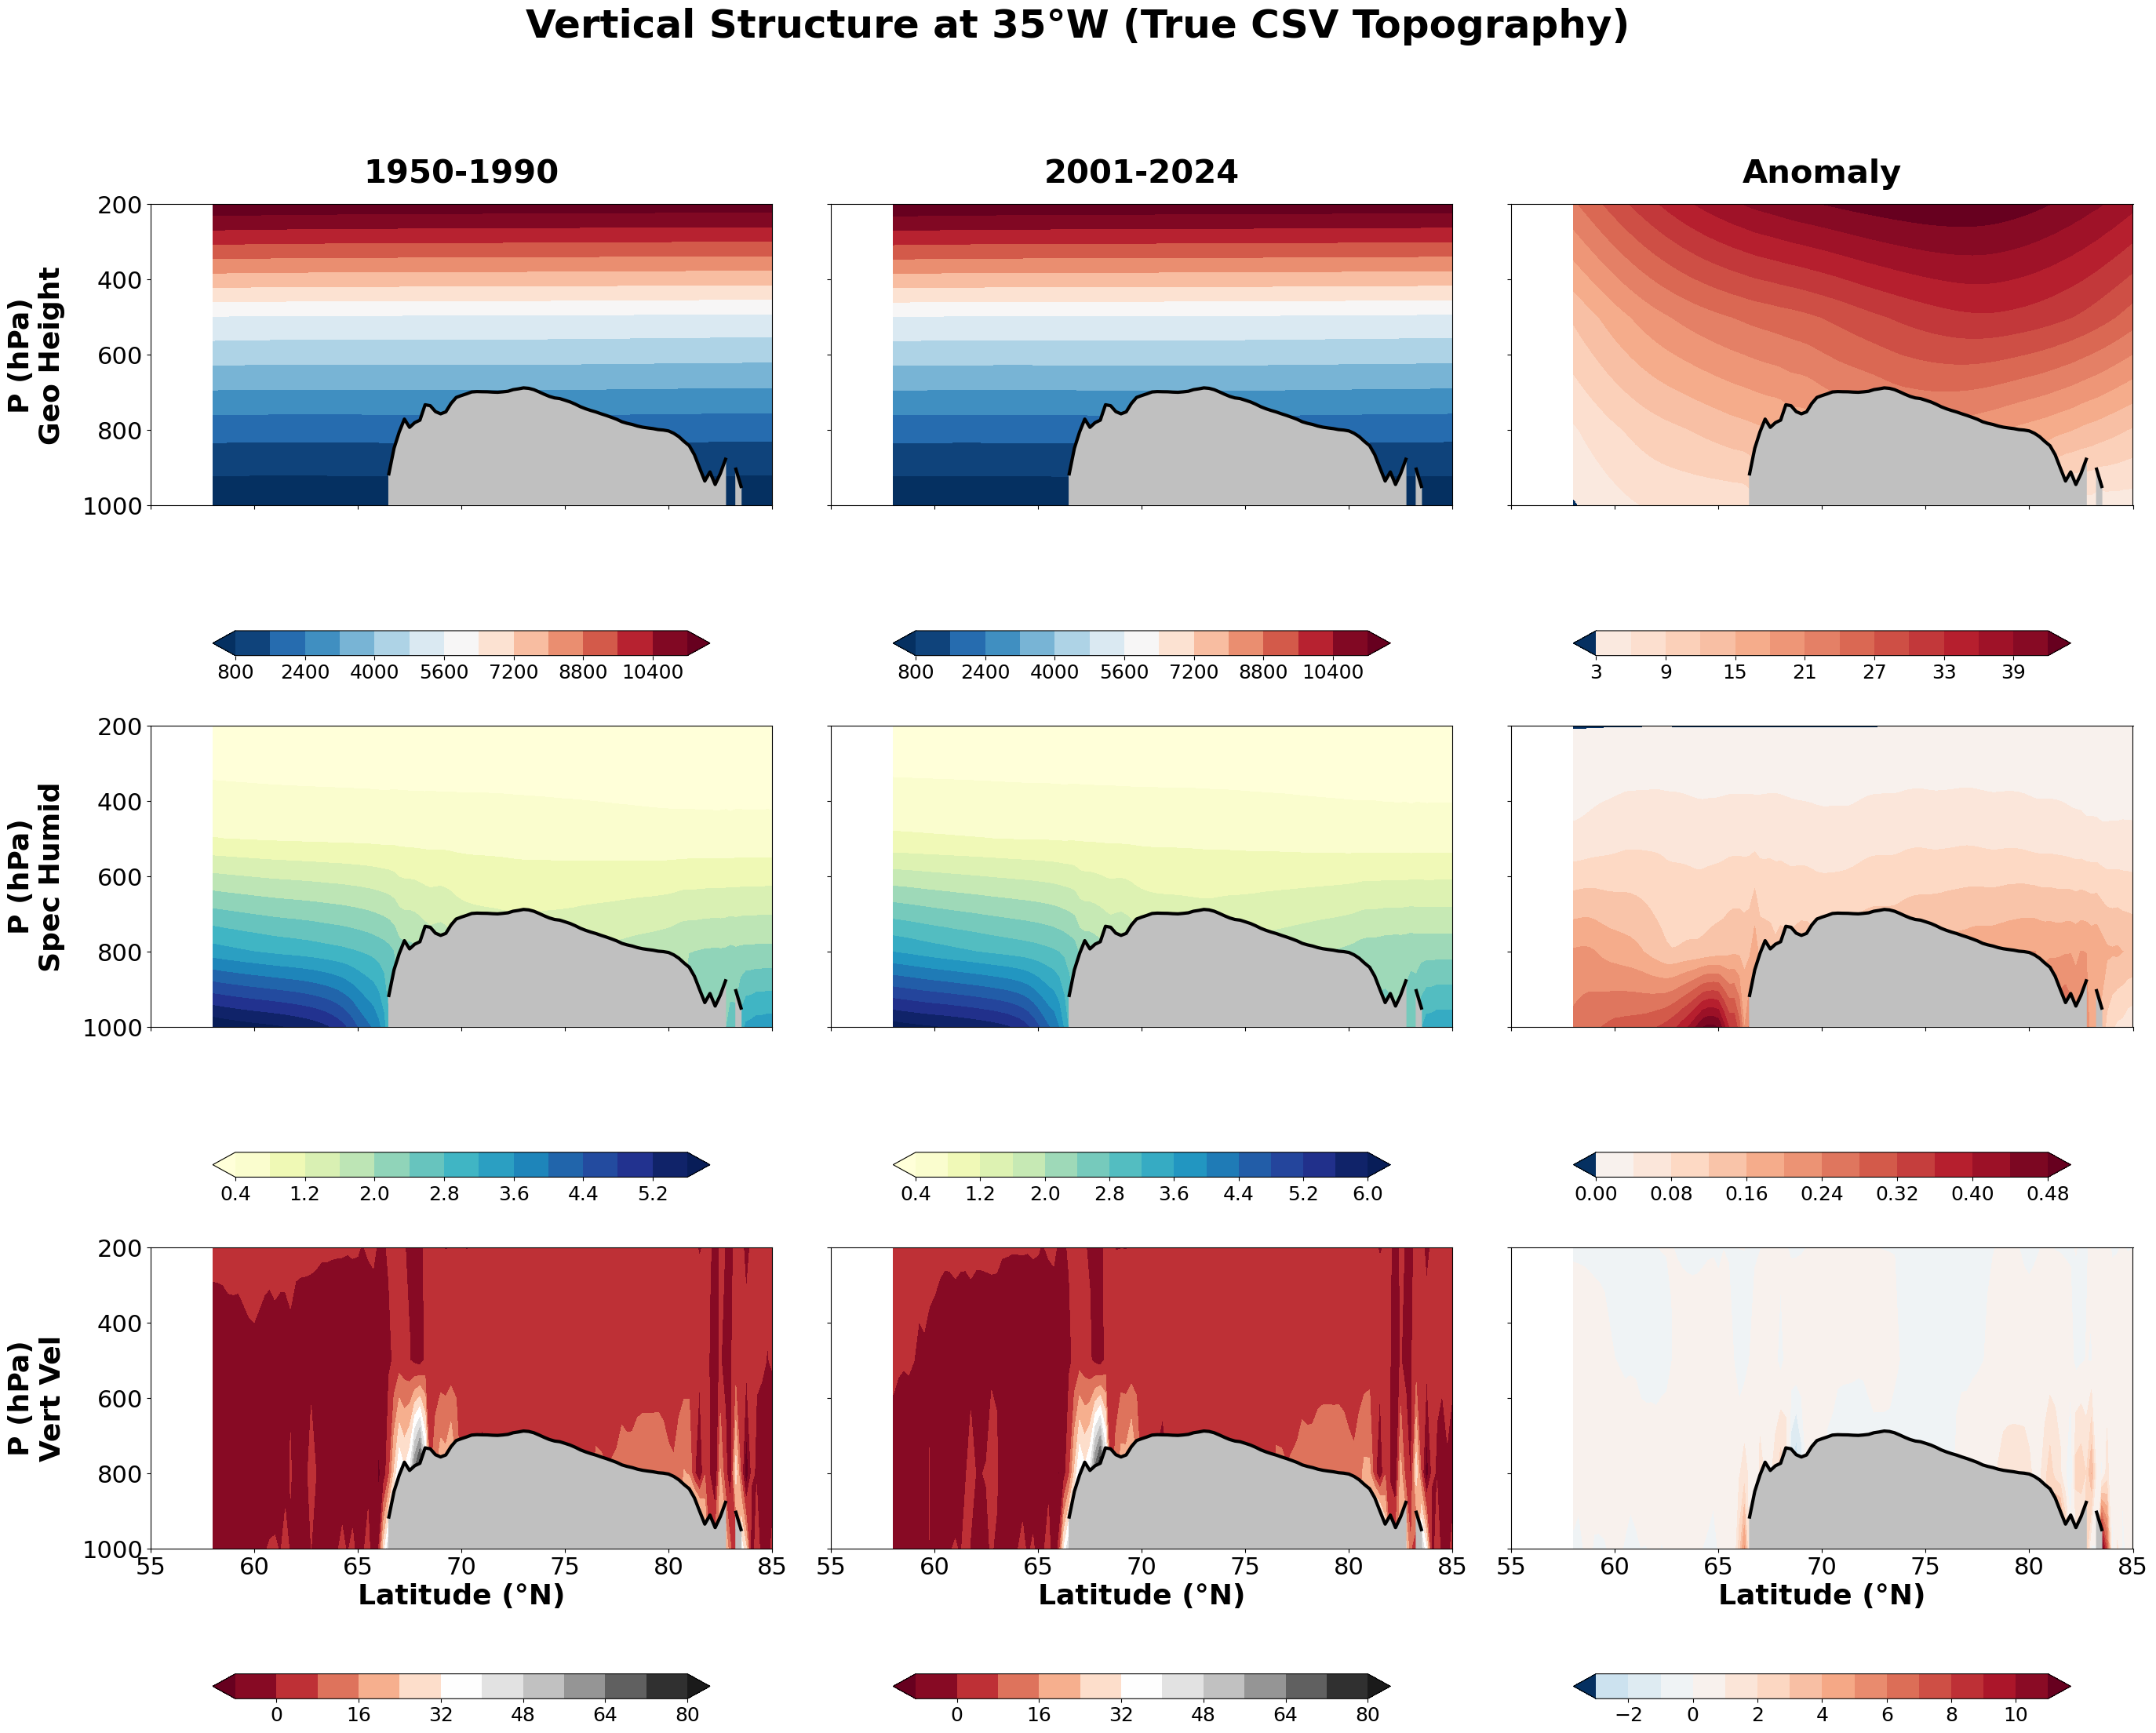

In [11]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

# ===================== 1. 路径与全局配置 =====================
NC_FILE = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature.csv"

TARGET_LONS = [-45, -40, -35]  # 目标经度

# 全局文字放大一倍
plt.rcParams.update({
    'font.size': 24,           
    'axes.titlesize': 30,      
    'axes.labelsize': 26,      
    'xtick.labelsize': 22,     
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 36     
})

# ===================== 2. 数据处理：时间切片与均值 =====================
ds = xr.open_dataset(NC_FILE)
T_DIM = 'valid_time'
Z_DIM = 'pressure_level'

# 计算两个时段的平均态 (根据你的228个时间步自动匹配)
m1 = ds.sel({T_DIM: slice('1950', '1990')}).mean(T_DIM)
m2 = ds.sel({T_DIM: slice('2001', '2024')}).mean(T_DIM)
anom = m2 - m1

# 变量配置 (z/9.80665 转换位势高度为米)
VARIABLES = [
    {'code': 'z', 'name': 'Geo Height', 'cmap': 'RdBu_r', 'unit': 'm', 'scale': 1/9.80665},
    {'code': 'q', 'name': 'Spec Humid', 'cmap': 'YlGnBu', 'unit': 'g/kg', 'scale': 1e3},
    {'code': 'w', 'name': 'Vert Vel', 'cmap': 'RdGy', 'unit': 'Pa/s*100', 'scale': 100}
]

LEVELS_VALS = ds[Z_DIM].values
LATS = ds.latitude.values  # 改为使用纬度坐标

# ===================== 3. 核心修正：从 CSV 提取真实地形并映射到气压轴 =====================
def get_csv_terrain_hPa(lats_target, target_lon):
    """
    1. 从 CSV 读取海拔 (m)
    2. 将海拔转换为对应的地面气压 (hPa)，以便画在 P 坐标轴上
    
    参数:
        lats_target: 目标纬度数组
        target_lon: 目标经度值
    """
    df = pd.read_csv(CSV_PATH)
    
    # 匹配经度：处理多位小数，寻找最接近 target_lon 的行
    mask = np.isclose(df['longitude'], target_lon, atol=0.1)
    df_lon = df[mask].copy()
    
    if df_lon.empty:
        print(f"警告：CSV 中找不到经度 {target_lon} 附近的数据")
        return np.full_like(lats_target, 1013.25)

    # 排序并去重
    df_lon = df_lon.sort_values('latitude').drop_duplicates('latitude')
    
    # 线性插值处理缺失值
    f_interp = interp1d(df_lon['latitude'], df_lon['altitude'], 
                        kind='linear', bounds_error=False, fill_value="extrapolate")
    topo_m = f_interp(lats_target)

    # 关键转换：海拔 (m) -> 气压 (hPa)
    # 使用标准大气压公式，保证 3000m 对应约 700hPa
    topo_hPa = 1013.25 * (1 - 2.25577e-5 * topo_m)**5.25588
    
    # 限制范围，防止转换出的气压超出绘图边界
    topo_hPa = np.clip(topo_hPa, 200, 1013.25)
    return topo_hPa

# ===================== 4. 绘图循环 =====================
for lon in TARGET_LONS:
    fig, axes = plt.subplots(3, 3, figsize=(28, 24), sharex=True, sharey=True)
    
    # 获取基于 CSV 的真实地形边界 (单位: hPa)
    topo_hPa = get_csv_terrain_hPa(LATS, lon)
    
    for r, var in enumerate(VARIABLES):
        v_code = var['code']
        factor = var.get('scale', 1.0)
        
        # 数据准备 - 沿经度切片
        d1 = m1[v_code].sel(longitude=lon, method='nearest').compute() * factor
        d2 = m2[v_code].sel(longitude=lon, method='nearest').compute() * factor
        da = anom[v_code].sel(longitude=lon, method='nearest').compute() * factor
        
        plot_list = [d1, d2, da]
        
        for c in range(3):
            ax = axes[r, c]
            curr_data = plot_list[c]
            
            # 填色设置
            cmap = var['cmap'] if c < 2 else 'RdBu_r'
            if c == 2:
                vmax = np.abs(curr_data).max().compute()
                vmin, vmax = -vmax, vmax
            else:
                vmin, vmax = None, None

            # 绘图 - X轴为纬度，Y轴为气压层
            im = ax.contourf(LATS, LEVELS_VALS, curr_data, levels=15, 
                             cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
            
            # --- 绘制真实地形遮罩 ---
            # 灰区从地表气压(topo_hPa)填充到图底(1050)
            ax.fill_between(LATS, topo_hPa, 1100, color='silver', zorder=10)
            ax.plot(LATS, topo_hPa, color='black', linewidth=3, zorder=11)
            
            # 坐标轴与标签
            ax.set_ylim(1000, 200) 
            ax.set_xlim(55, 85)  # 聚焦格陵兰地区纬度范围
            
            if r == 0: ax.set_title(['1950-1990', '2001-2024', 'Anomaly'][c], weight='bold', pad=20)
            if c == 0: ax.set_ylabel(f"P (hPa)\n{var['name']}", weight='bold', labelpad=15)
            if r == 2: ax.set_xlabel("Latitude (°N)", weight='bold')
            
            # 色标
            cb = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.25, shrink=0.8)
            cb.ax.tick_params(labelsize=18)

    # 转换经度显示格式：负数用W表示
    lon_label = f"{abs(lon)}°W" if lon < 0 else f"{lon}°E"
    plt.suptitle(f"Vertical Structure at {lon_label} (True CSV Topography)", weight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    plt.show()

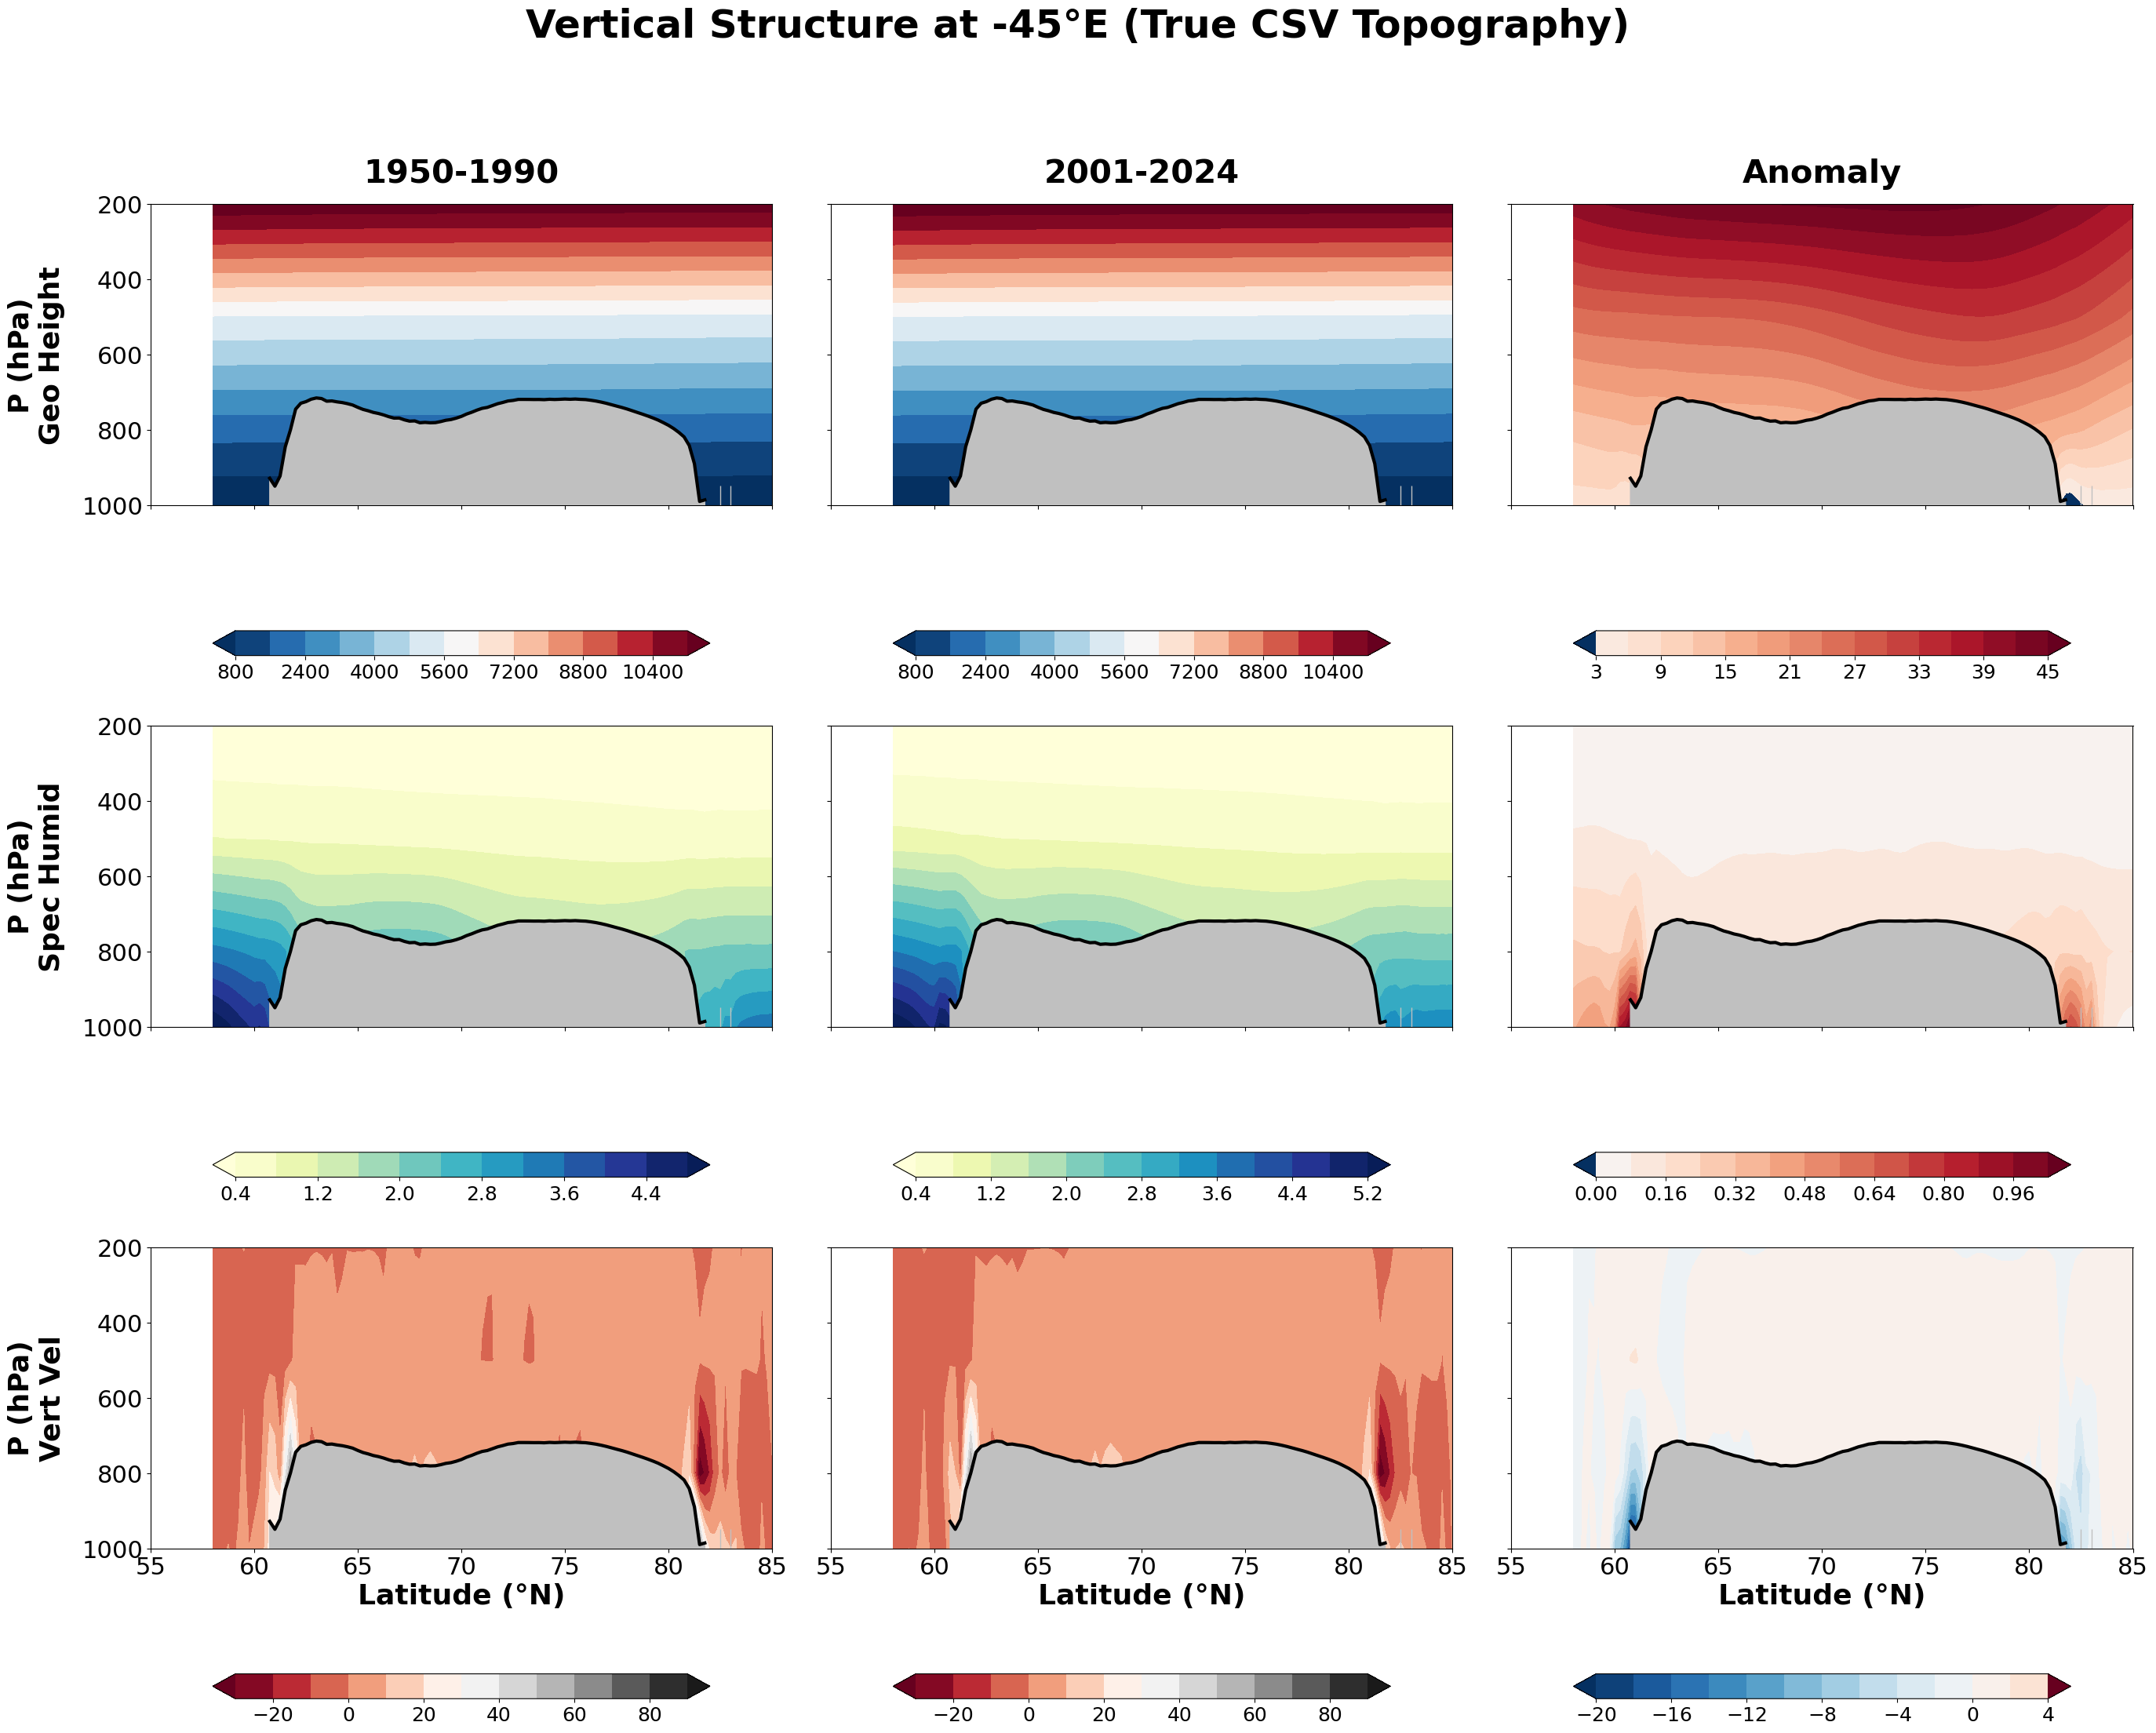

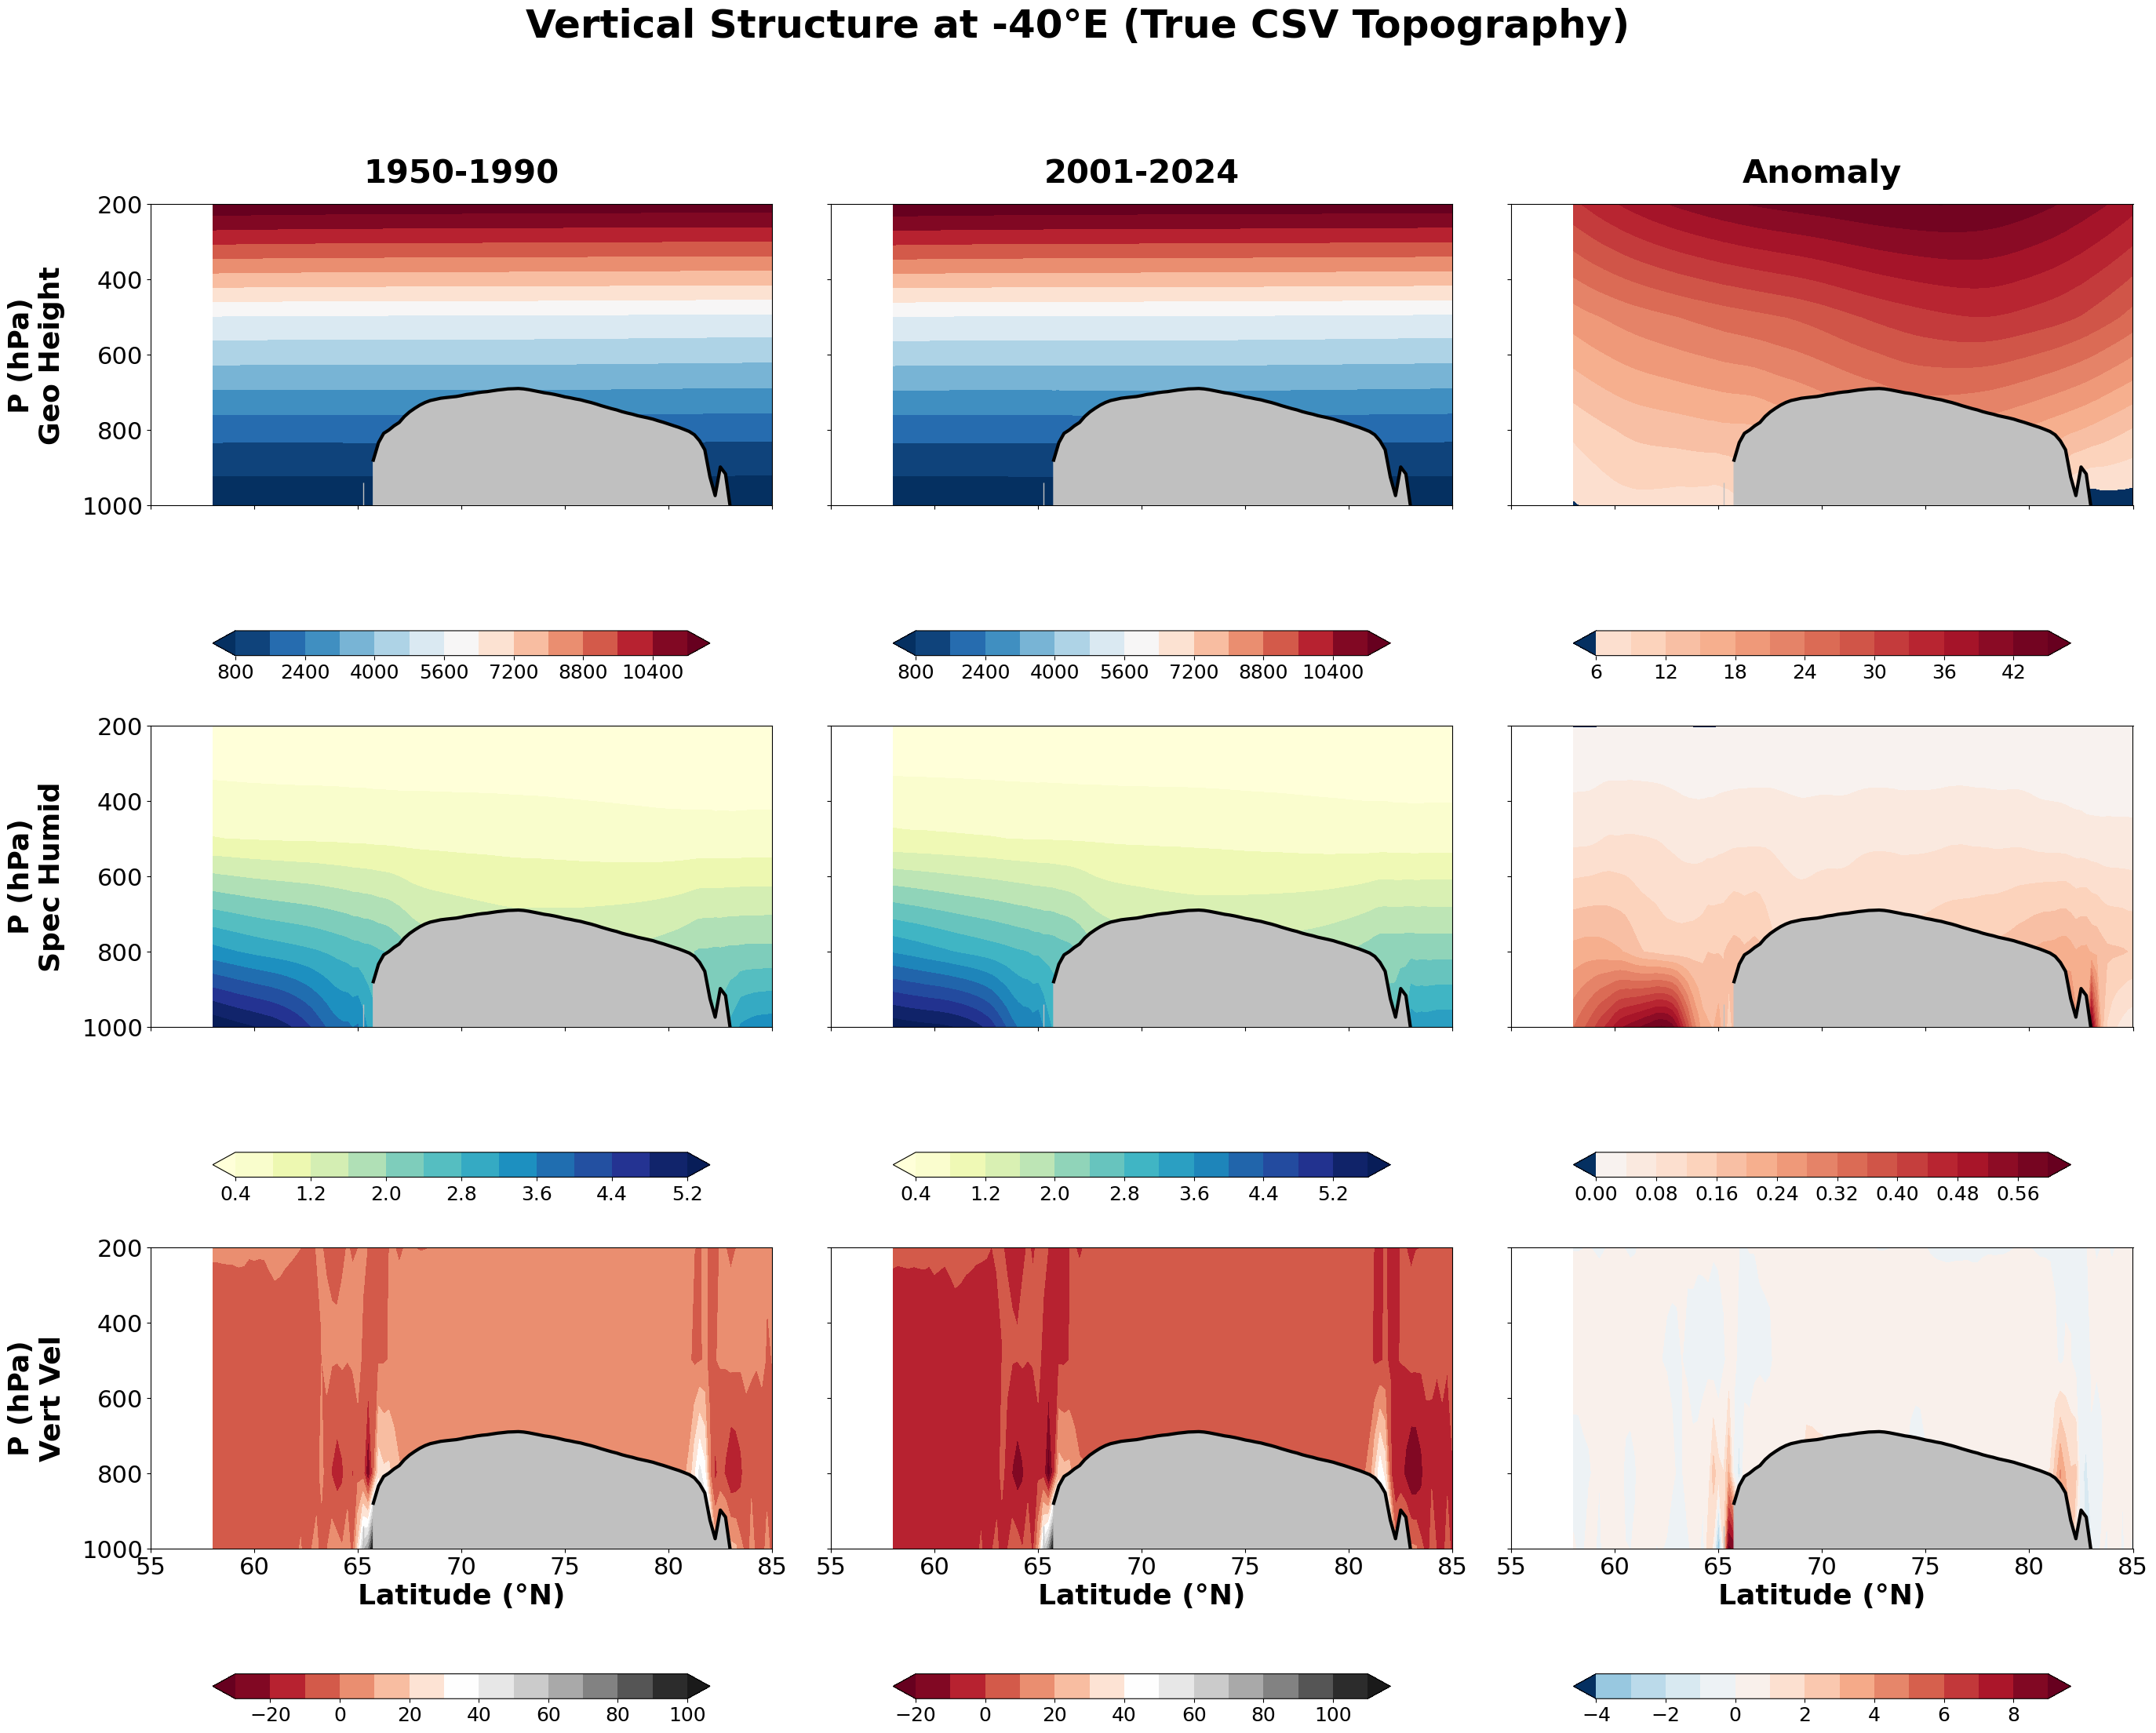

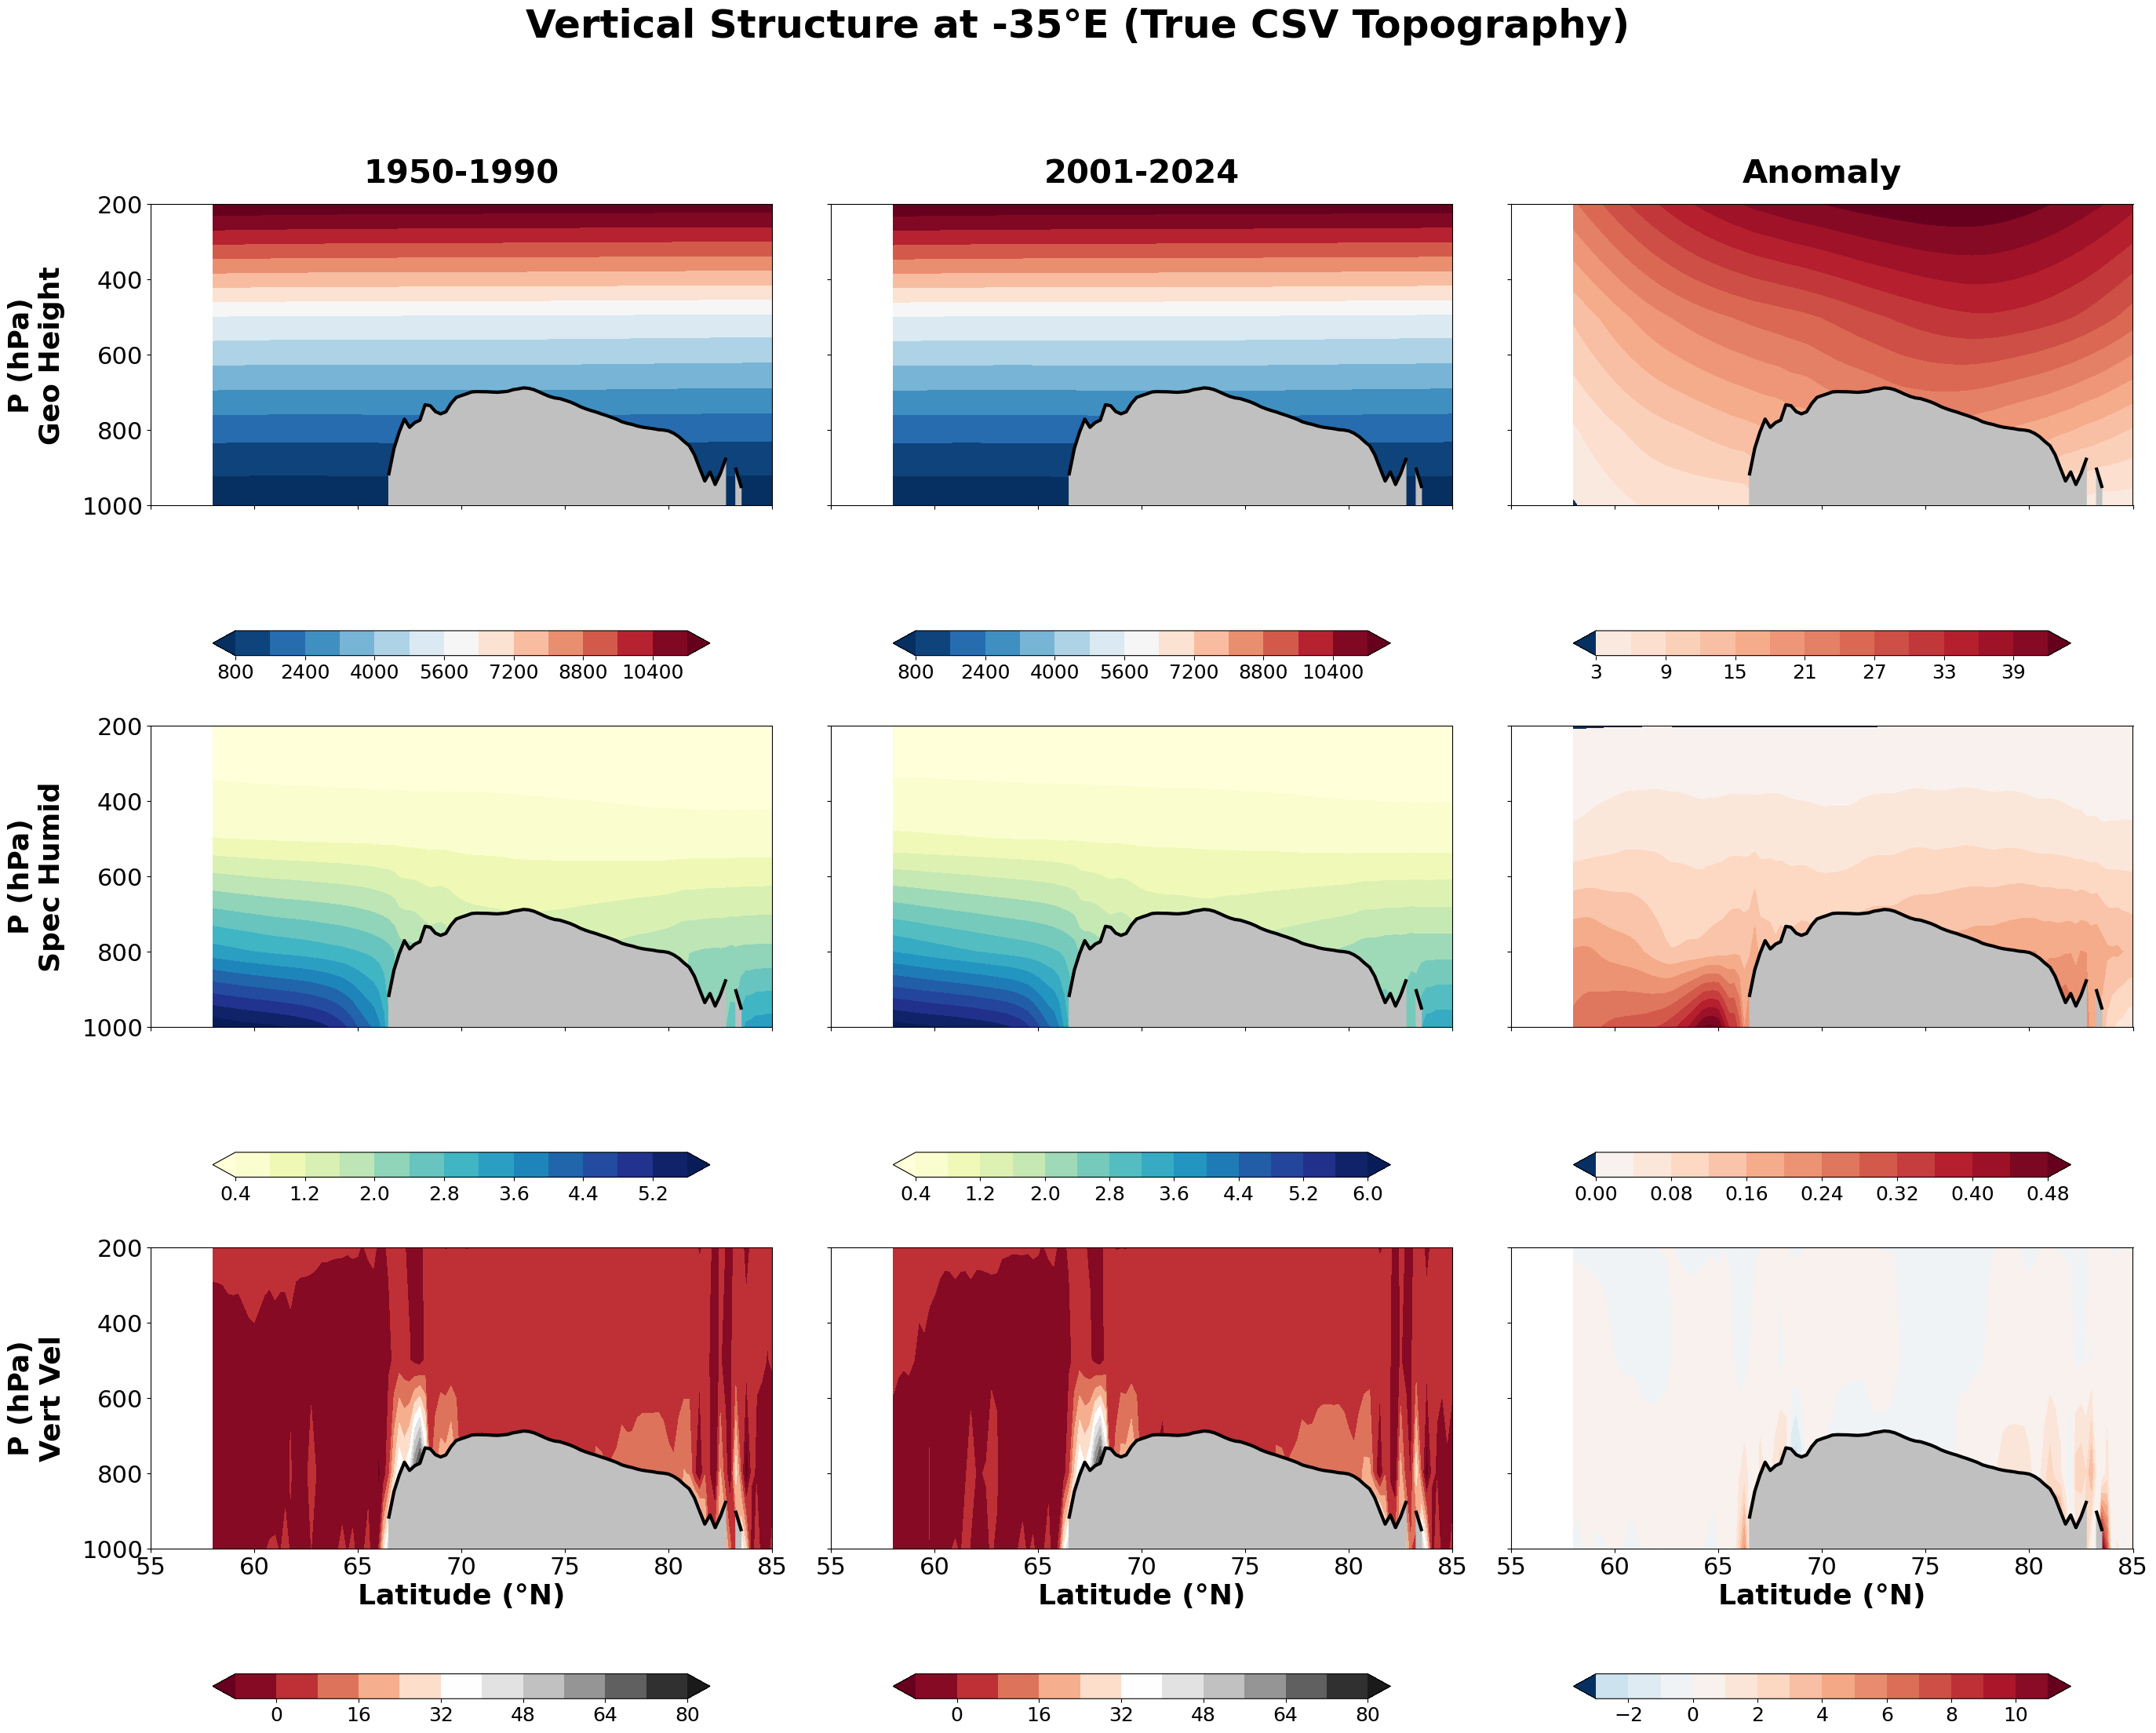

In [10]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

# ===================== 1. 路径与全局配置 =====================
NC_FILE = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature.csv"

TARGET_LONS = [-45, -40, -35]  # 目标经度

# 全局文字放大一倍
plt.rcParams.update({
    'font.size': 24,           
    'axes.titlesize': 30,      
    'axes.labelsize': 26,      
    'xtick.labelsize': 22,     
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 36     
})

# ===================== 2. 数据处理：时间切片与均值 =====================
ds = xr.open_dataset(NC_FILE)
T_DIM = 'valid_time'
Z_DIM = 'pressure_level'

# 计算两个时段的平均态 (根据你的228个时间步自动匹配)
m1 = ds.sel({T_DIM: slice('1950', '1990')}).mean(T_DIM)
m2 = ds.sel({T_DIM: slice('2001', '2024')}).mean(T_DIM)
anom = m2 - m1

# 变量配置 (z/9.80665 转换位势高度为米)
VARIABLES = [
    {'code': 'z', 'name': 'Geo Height', 'cmap': 'RdBu_r', 'unit': 'm', 'scale': 1/9.80665},
    {'code': 'q', 'name': 'Spec Humid', 'cmap': 'YlGnBu', 'unit': 'g/kg', 'scale': 1e3},
    {'code': 'w', 'name': 'Vert Vel', 'cmap': 'RdGy', 'unit': 'Pa/s*100', 'scale': 100}
]

LEVELS_VALS = ds[Z_DIM].values
LATS = ds.latitude.values  # 改为使用纬度坐标

# ===================== 3. 核心修正：从 CSV 提取真实地形并映射到气压轴 =====================
def get_csv_terrain_hPa(lats_target, target_lon):
    """
    1. 从 CSV 读取海拔 (m)
    2. 将海拔转换为对应的地面气压 (hPa)，以便画在 P 坐标轴上
    
    参数:
        lats_target: 目标纬度数组
        target_lon: 目标经度值
    """
    df = pd.read_csv(CSV_PATH)
    
    # 匹配经度：处理多位小数，寻找最接近 target_lon 的行
    mask = np.isclose(df['longitude'], target_lon, atol=0.1)
    df_lon = df[mask].copy()
    
    if df_lon.empty:
        print(f"警告：CSV 中找不到经度 {target_lon} 附近的数据")
        return np.full_like(lats_target, 1013.25)

    # 排序并去重
    df_lon = df_lon.sort_values('latitude').drop_duplicates('latitude')
    
    # 线性插值处理缺失值
    f_interp = interp1d(df_lon['latitude'], df_lon['altitude'], 
                        kind='linear', bounds_error=False, fill_value="extrapolate")
    topo_m = f_interp(lats_target)

    # 关键转换：海拔 (m) -> 气压 (hPa)
    # 使用标准大气压公式，保证 3000m 对应约 700hPa
    topo_hPa = 1013.25 * (1 - 2.25577e-5 * topo_m)**5.25588
    
    # 限制范围，防止转换出的气压超出绘图边界
    topo_hPa = np.clip(topo_hPa, 200, 1013.25)
    return topo_hPa

# ===================== 4. 绘图循环 =====================
for lon in TARGET_LONS:
    fig, axes = plt.subplots(3, 3, figsize=(28, 24), sharex=True, sharey=True)
    
    # 获取基于 CSV 的真实地形边界 (单位: hPa)
    topo_hPa = get_csv_terrain_hPa(LATS, lon)
    
    for r, var in enumerate(VARIABLES):
        v_code = var['code']
        factor = var.get('scale', 1.0)
        
        # 数据准备 - 沿经度切片
        d1 = m1[v_code].sel(longitude=lon, method='nearest').compute() * factor
        d2 = m2[v_code].sel(longitude=lon, method='nearest').compute() * factor
        da = anom[v_code].sel(longitude=lon, method='nearest').compute() * factor
        
        plot_list = [d1, d2, da]
        
        for c in range(3):
            ax = axes[r, c]
            curr_data = plot_list[c]
            
            # 填色设置
            cmap = var['cmap'] if c < 2 else 'RdBu_r'
            if c == 2:
                vmax = np.abs(curr_data).max().compute()
                vmin, vmax = -vmax, vmax
            else:
                vmin, vmax = None, None

            # 绘图 - X轴为纬度，Y轴为气压层
            im = ax.contourf(LATS, LEVELS_VALS, curr_data, levels=15, 
                             cmap=cmap, vmin=vmin, vmax=vmax, extend='both')
            
            # --- 绘制真实地形遮罩 ---
            # 灰区从地表气压(topo_hPa)填充到图底(1050)
            ax.fill_between(LATS, topo_hPa, 1100, color='silver', zorder=10)
            ax.plot(LATS, topo_hPa, color='black', linewidth=3, zorder=11)
            
            # 坐标轴与标签
            ax.set_ylim(1000, 200) 
            ax.set_xlim(55, 85)  # 聚焦格陵兰地区纬度范围
            
            if r == 0: ax.set_title(['1950-1990', '2001-2024', 'Anomaly'][c], weight='bold', pad=20)
            if c == 0: ax.set_ylabel(f"P (hPa)\n{var['name']}", weight='bold', labelpad=15)
            if r == 2: ax.set_xlabel("Latitude (°N)", weight='bold')
            
            # 色标
            cb = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.25, shrink=0.8)
            cb.ax.tick_params(labelsize=18)

    plt.suptitle(f"Vertical Structure at {lon}°E (True CSV Topography)", weight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    plt.show()

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ===================== 1. 模拟真实地形函数 =====================
# 为了接近 Fig. 5 的效果，我们需要一个简单的格陵兰地形剖面
def get_greenland_topography(lons):
    """
    根据经度返回格陵兰大致的冰盖高度（单位：hPa）
    格陵兰大致范围：-70W 到 -20W，中心高，四周低
    """
    topo = np.full_like(lons, 1013.0) # 海平面底部
    # 模拟冰盖中心（约 -40W）高度可达 3000m (约 700hPa)
    mask = (lons > -60) & (lons < -25)
    # 使用余弦波模拟平滑冰盖
    topo[mask] = 1013 - (1013 - 650) * np.cos(np.pi * (lons[mask] + 42.5) / 35)**2
    return topo

# ===================== 2. 绘图逻辑优化 =====================
def plot_refined_sections(m1, m2, anom, lat_range=(68, 72)):
    # 纬向平均
    d1 = m1.sel(latitude=slice(lat_range[0], lat_range[1])).mean('latitude')
    d2 = m2.sel(latitude=slice(lat_range[0], lat_range[1])).mean('latitude')
    da = anom.sel(latitude=slice(lat_range[0], lat_range[1])).mean('latitude')
    
    periods = [d1, d2, da]
    titles = ['1950-1990 Mean', '2001-2024 Mean', 'Anomaly (P2-P1)']
    vars_to_plot = ['w', 'z'] # 垂直速度和位势高度
    
    fig, axes = plt.subplots(2, 3, figsize=(20, 10), sharex=True, sharey=True)
    lons = d1.longitude.values
    topo_line = get_greenland_topography(lons)

    for r, v_code in enumerate(vars_to_plot):
        # 确定色标范围
        if v_code == 'w':
            cmap, label = 'RdGy', 'Vert Vel (Pa/s)'
            norm_val = 0.05 # 距平范围
        else:
            cmap, label = 'RdBu_r', 'Geo Height (m)'
            norm_val = 10 # 距平范围

        for c, data in enumerate(periods):
            ax = axes[r, c]
            
            # 准备绘图数据：由于只有两层，我们进行垂直线性插值以填满 800-1000 空间
            levels = [800, 1000]
            vals = data[v_code].values # [level, lon]
            
            # 使用 contourf 渲染
            im = ax.contourf(lons, levels, vals, levels=20, cmap=cmap, extend='both')
            
            # 绘制地形遮罩（模仿 Fig. 5）
            ax.fill_between(lons, topo_line, 1050, color='silver', zorder=10)
            ax.plot(lons, topo_line, color='black', linewidth=1.5, zorder=11)

            # 设置坐标
            ax.set_ylim(1000, 800) # 压力坐标翻转
            if r == 0: ax.set_title(titles[c], fontweight='bold', fontsize=15)
            if c == 0: ax.set_ylabel(f"Pressure (hPa)\n{label}", fontweight='bold')
            
            # 添加色标
            plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.15, shrink=0.8)

    plt.suptitle(f"Zonal Cross-section ({lat_range[0]}N-{lat_range[1]}N) - Evidence for Western Albedo", 
                 fontsize=18, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# 调用函数 (假设 m1, m2, anom 已根据之前的脚本计算完成)
# plot_refined_sections(m1, m2, anom)

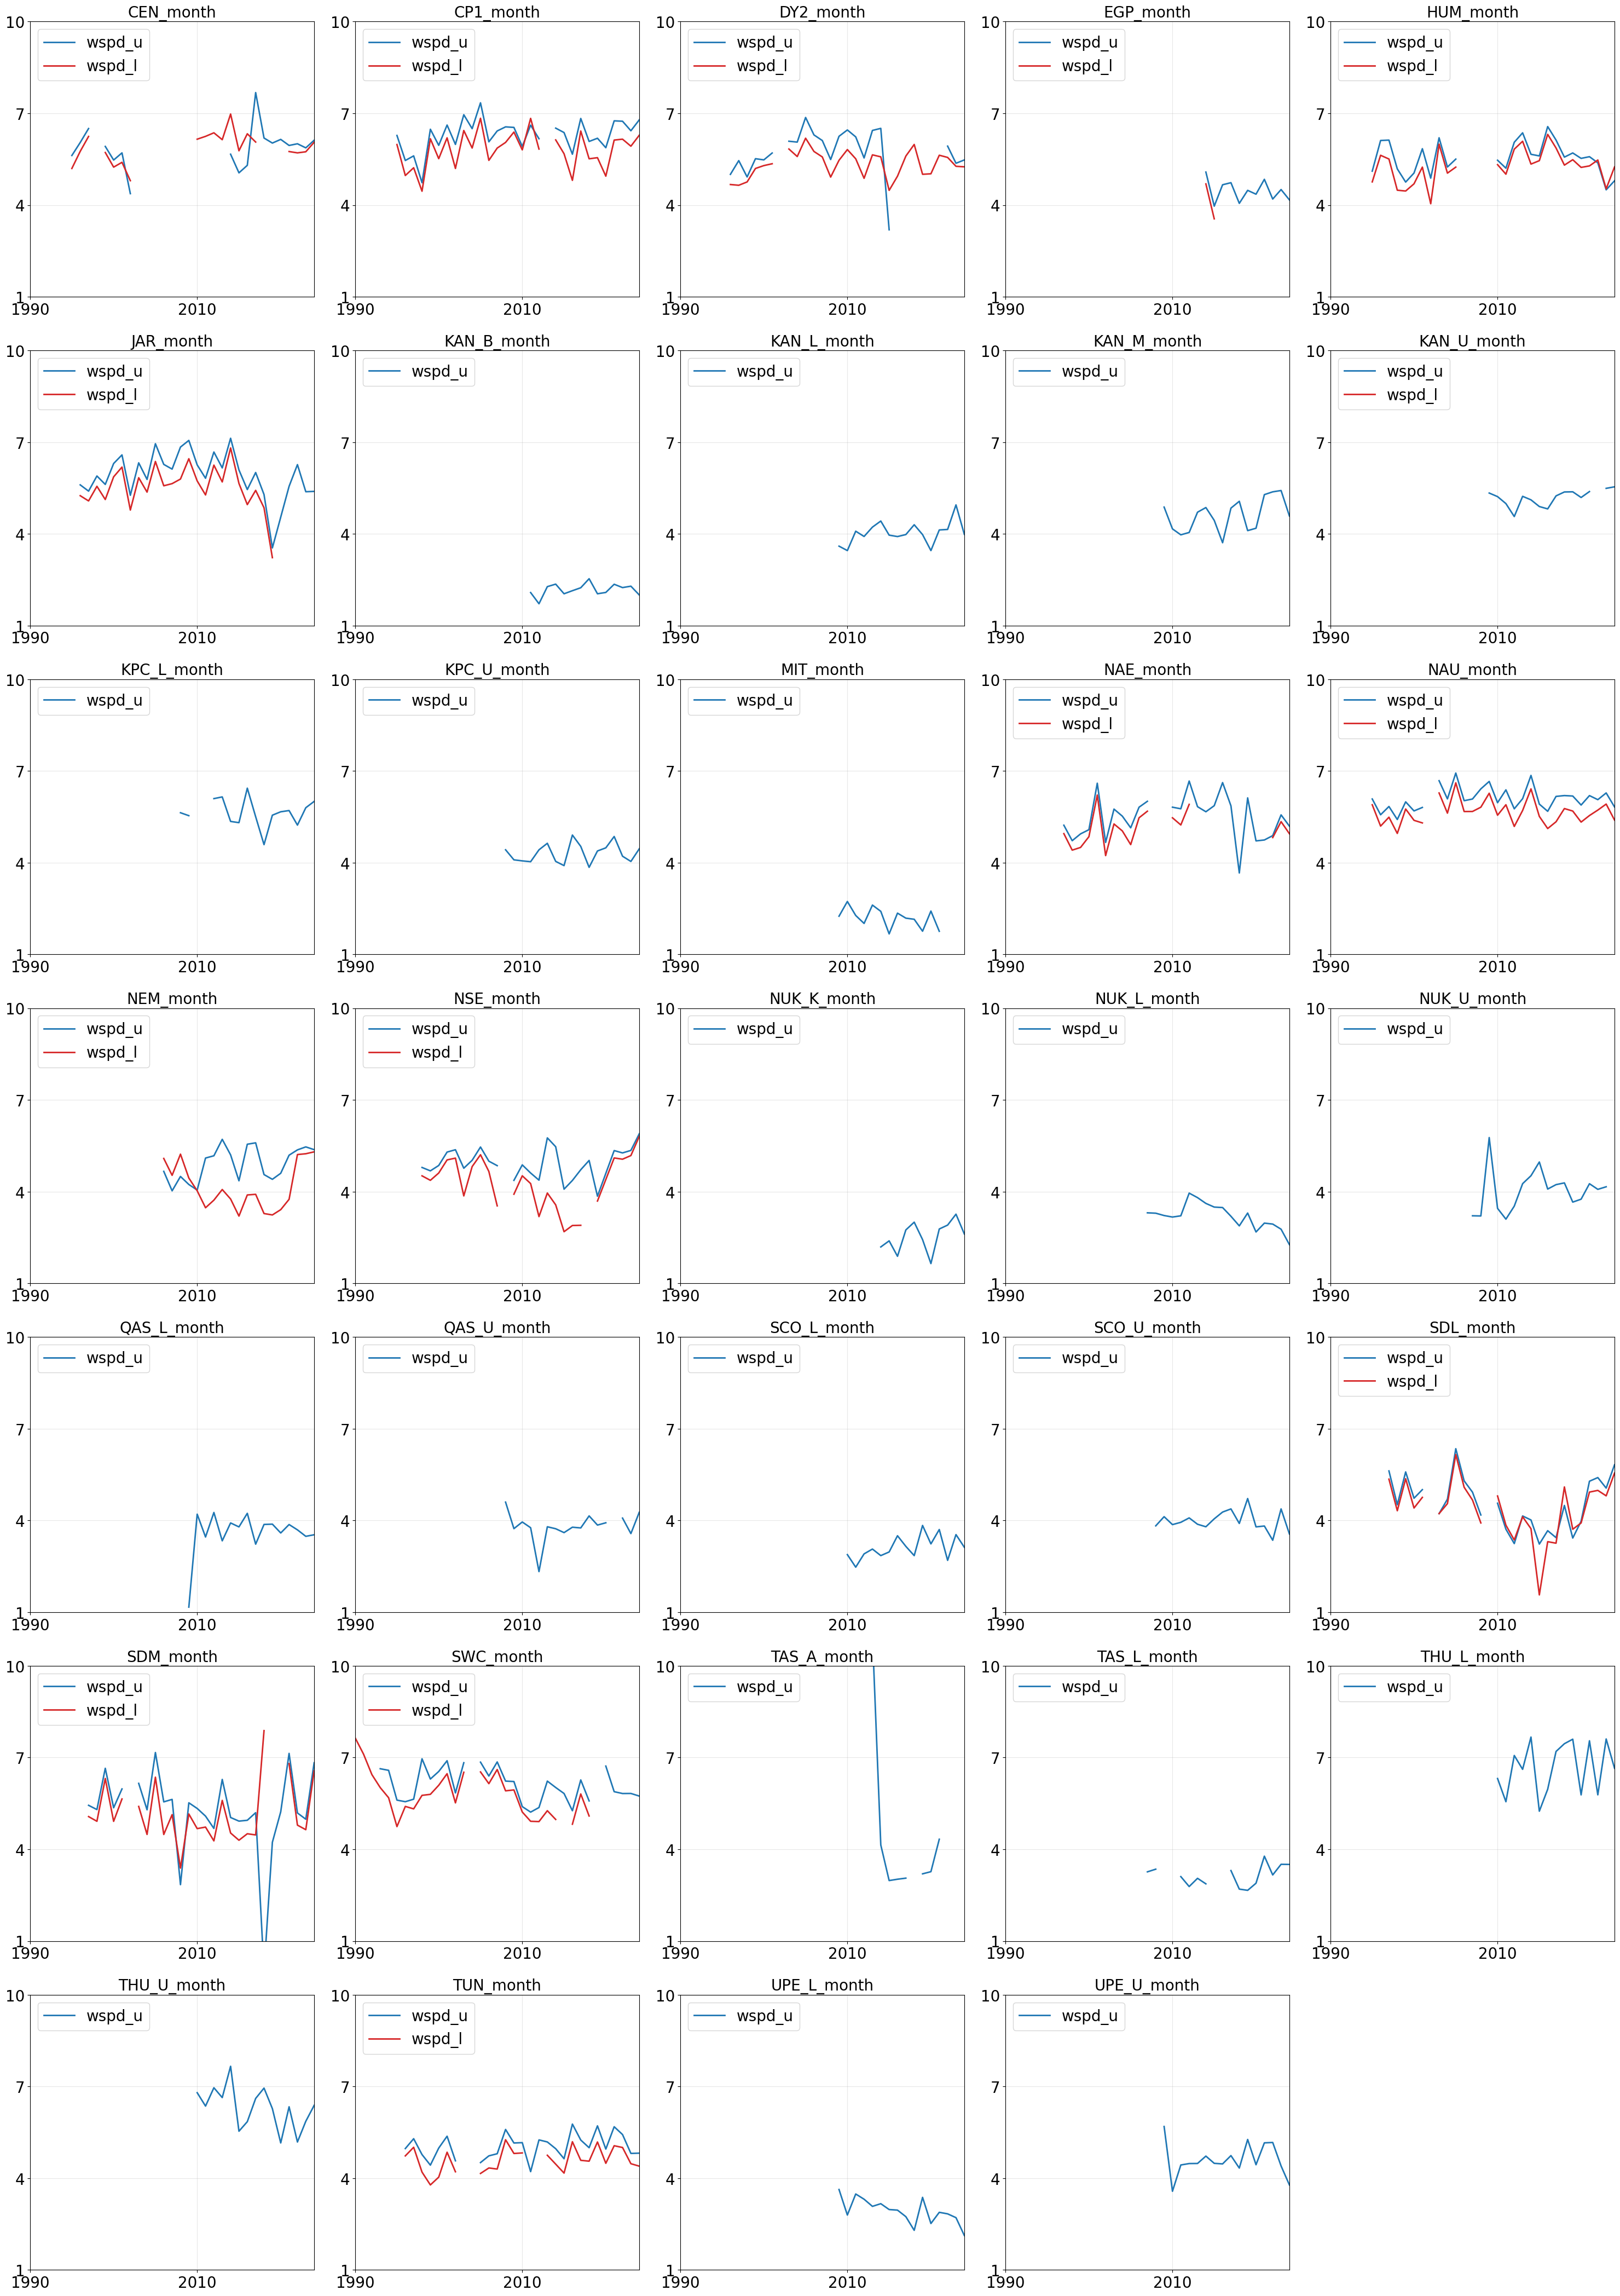


⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：
 ➤ TAS_A_month



In [11]:
# -*- coding: utf-8 -*-
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ===================== 参数 =====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\month"

START_YEAR = 1990
END_YEAR   = 2024

TREND_THRESHOLD = 0.1  # 斜率变化阈值 (m/s 每年)

# 全局大字号
plt.rcParams["font.size"] = 20
plt.rcParams["axes.titlesize"] = 20
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["legend.fontsize"] = 20

COLORS = {"wspd_u": "tab:blue", "wspd_l": "tab:red"}

# ===================== 扫描文件 =====================
files = [f for f in os.listdir(BASE_DIR) if f.endswith(".csv") and "month" in f.lower()]
files = sorted(files)

# ===================== 画布布局 =====================
n = len(files)
cols = 5
rows = (n // cols) + (1 if n % cols else 0)

fig, axes = plt.subplots(rows, cols, figsize=(30, 6 * rows))
axes = axes.flatten()

trend_stations = []  # 存储趋势明显的站点名称
plot_idx = 0

# ===================== 趋势函数 =====================
def calc_trend(series):
    """对单站点单变量 series 做线性趋势，自动 dropna()，出错返回 None"""
    s = series.dropna()
    if len(s) < 5:  # 少于 5 年不计算趋势
        return None
    
    x = np.array(s.index).reshape(-1, 1)
    y = s.values.reshape(-1, 1)
    
    try:
        model = LinearRegression().fit(x, y)
        return model.coef_[0][0]  # slope (m/s per year)
    except:
        return None

# ===================== 主循环 =====================
for file in files:
    path = os.path.join(BASE_DIR, file)
    df = pd.read_csv(path)
    station = file.replace(".csv", "")

    # 时间列检查
    if "time" not in df.columns:
        continue

    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"])

    df = df[(df["time"].dt.year >= START_YEAR) & (df["time"].dt.year <= END_YEAR)]
    if df.empty:
        continue

    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month

    # 只取 JJA
    df_jja = df[df["month"].isin([6, 7, 8])]
    if df_jja.empty:
        continue

    # 聚合年均
    series_u = df_jja.groupby("year")["wspd_u"].mean() if "wspd_u" in df_jja.columns else None
    series_l = df_jja.groupby("year")["wspd_l"].mean() if "wspd_l" in df_jja.columns else None

    # wspd_u/l 都没有 → 跳过
    if (series_u is None) and (series_l is None):
        continue

    # 有效年份过滤（≥10 年）
    valid_years = set()
    if series_u is not None: valid_years |= set(series_u.index)
    if series_l is not None: valid_years |= set(series_l.index)

    if len(valid_years) < 10:
        continue

    # ===================== 趋势计算 =====================
    slope = None

    if series_u is not None:
        slope = calc_trend(series_u)

    if slope is None and series_l is not None:
        slope = calc_trend(series_l)

    trend_flag = False
    if slope is not None and abs(slope) >= TREND_THRESHOLD:
        trend_flag = True
        trend_stations.append(station)

    # ===================== 开始画图 =====================
    ax = axes[plot_idx]

    if series_u is not None:
        ax.plot(series_u.index, series_u.values, label="wspd_u",
                color=COLORS["wspd_u"], linewidth=2)

    if series_l is not None:
        ax.plot(series_l.index, series_l.values, label="wspd_l",
                color=COLORS["wspd_l"], linewidth=2)

    ax.set_title(station)
    ax.grid(alpha=0.3)

    # ---- x 轴 ----
    ax.set_xticks([1990, 2010])
    ax.set_xlim(1990, 2024)

    # ---- y 轴统一 ----
    ax.set_ylim(1, 10)
    ax.set_yticks([1, 4, 7, 10])

    ax.legend(loc="upper left")

    plot_idx += 1

# ==== 删除多余空子图 ====
for j in range(plot_idx, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# ===================== 输出明显趋势站点 =====================
print("\n==============================")
print("⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：")
for s in trend_stations:
    print(" ➤", s)
print("==============================\n")
